In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# Parámetros de la representación
xmin, xmax = -2.2, 1.0
ymin, ymax = -1.5, 1.5

# Resolución de la malla
ancho = 1200
alto = 1000

# Máximo de iteraciones
Nmax = 300

print("Parámetros establecidos correctamente.")
print("Resolución:", ancho, "x", alto)
print("Máximo de iteraciones:", Nmax)


Parámetros establecidos correctamente.
Resolución: 1200 x 1000
Máximo de iteraciones: 300


In [ ]:

# Coordenadas reales e imaginarias
x = np.linspace(xmin, xmax, ancho)
y = np.linspace(ymin, ymax, alto)

# Construcción de la malla del plano complejo
X, Y = np.meshgrid(x, y)

# Cada punto representa un parámetro complejo
C = X + 1j * Y

print("Malla compleja construida.")
print("Cantidad de parámetros:", C.size)


Malla compleja construida.
Cantidad de parámetros: 1200000


In [ ]:

def calcular_mandelbrot(C, Nmax):

    # Inicialización de la sucesión
    Z = np.zeros(C.shape, dtype=complex)

    # Registro de la primera iteración de escape
    iteraciones = np.zeros(C.shape, dtype=int)

    # Puntos que todavía no presentan escape
    activos = np.ones(C.shape, dtype=bool)

    for n in range(1, Nmax + 1):

        # Aplicar la recurrencia
        Z[activos] = Z[activos]**2 + C[activos]

        # Identificar los puntos que superan el radio 2
        escape = activos & (np.abs(Z) > 2)

        # Registrar la primera iteración de escape
        iteraciones[escape] = n

        # Retirar los puntos que ya escaparon
        activos[escape] = False

        if not np.any(activos):
            break

    return iteraciones

# Ejecutar el procedimiento
resultado = calcular_mandelbrot(C, Nmax)

print("Cálculo terminado.")


Cálculo terminado.


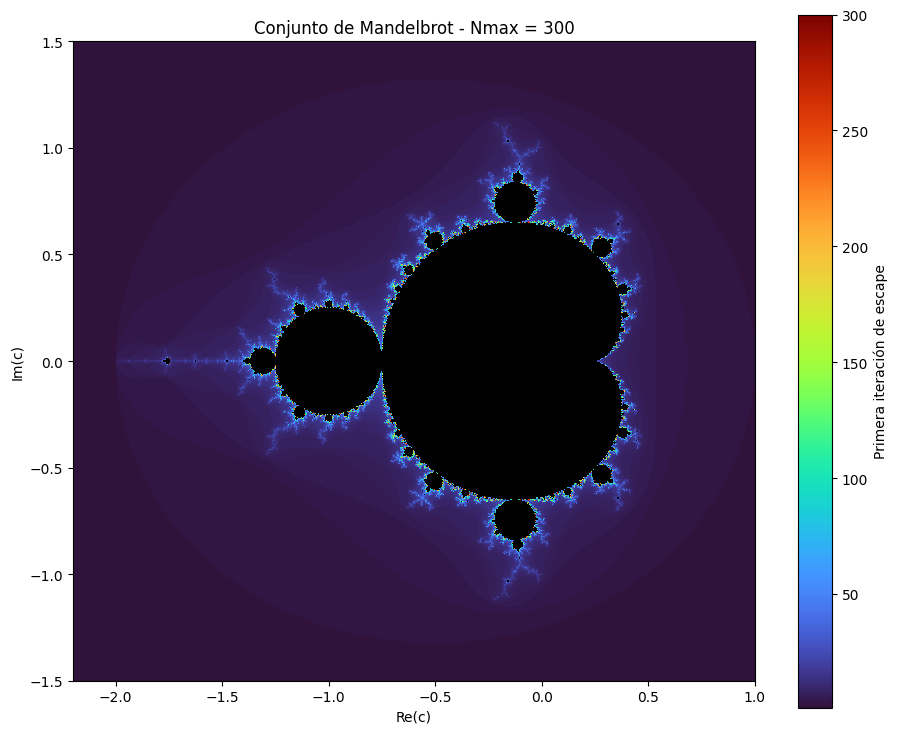

In [ ]:

plt.figure(figsize=(11, 9))

imagen = plt.imshow(
    resultado,
    extent=[xmin, xmax, ymin, ymax],
    origin="lower",
    cmap="turbo",
    interpolation="nearest",
    vmin=1,
    vmax=Nmax
)

# Los puntos sin escape detectado se representan en negro
imagen.cmap.set_under("black")

plt.colorbar(imagen, label="Primera iteración de escape")

plt.xlabel("Re(c)")
plt.ylabel("Im(c)")

plt.title(
    f"Conjunto de Mandelbrot - Nmax = {Nmax}"
)

plt.savefig(
    "Figura_1_Mandelbrot_300.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


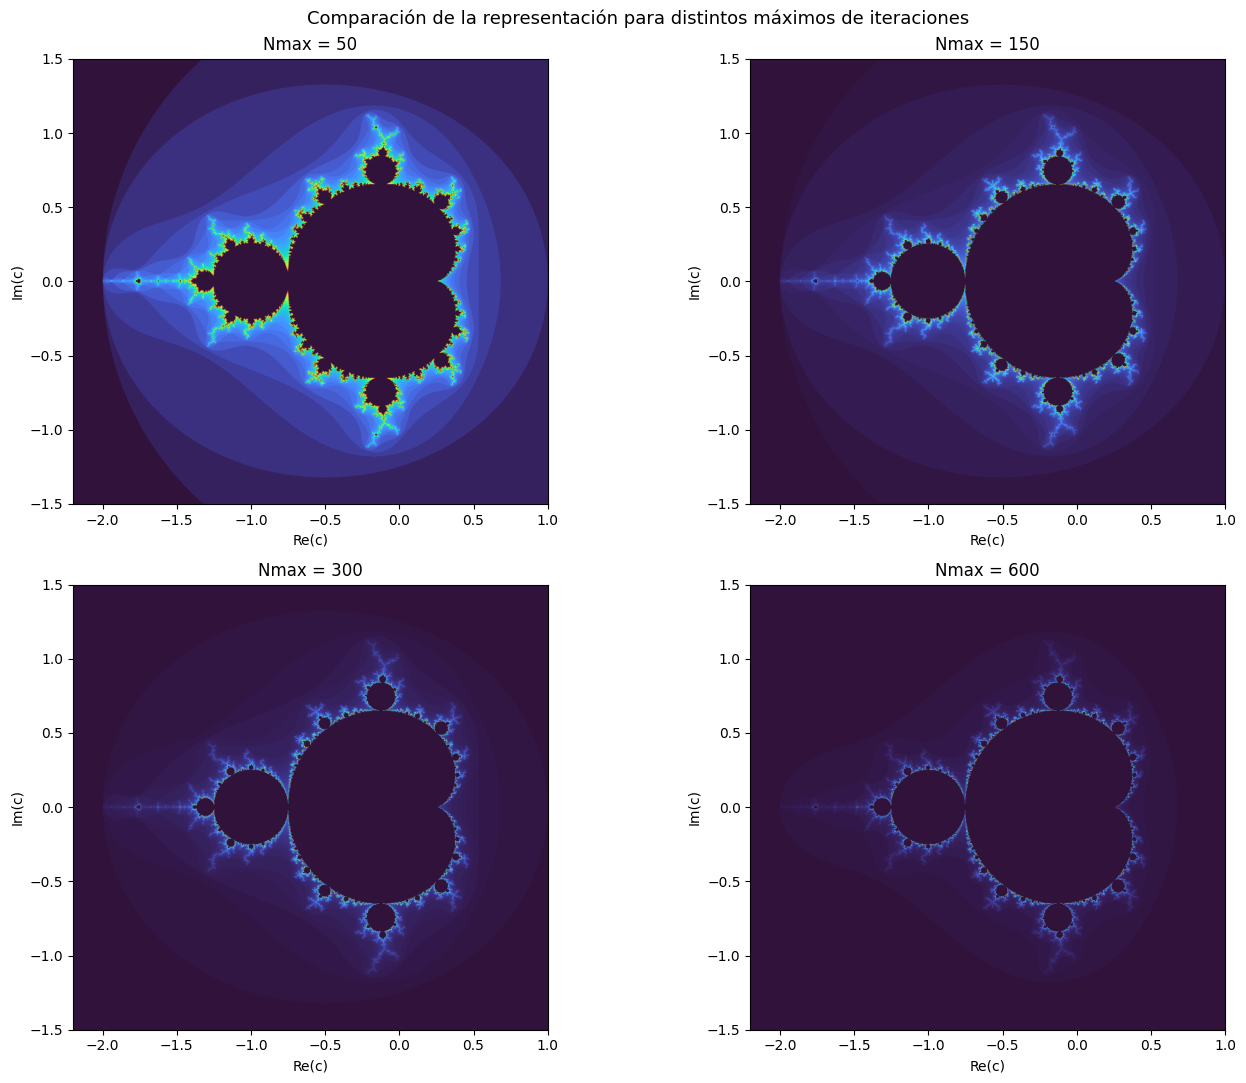

In [ ]:

valores_N = [50, 150, 300, 600]

fig, ejes = plt.subplots(2, 2, figsize=(14, 11))

for ax, N in zip(ejes.flat, valores_N):

    datos = calcular_mandelbrot(C, N)

    ax.imshow(
        datos,
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap="turbo",
        vmin=1,
        vmax=N
    )

    ax.set_title(f"Nmax = {N}")
    ax.set_xlabel("Re(c)")
    ax.set_ylabel("Im(c)")

plt.suptitle(
    "Comparación de la representación para distintos máximos de iteraciones",
    fontsize=13
)

plt.tight_layout()

plt.savefig(
    "Figura_2_Comparacion_iteraciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# Clasificación de los puntos:
# True: no se detectó escape
# False: se detectó escape

clasificacion = (resultado == 0)

alto, ancho = clasificacion.shape

# Ampliamos la matriz para examinar los vecinos
P = np.pad(clasificacion, 1, mode="edge")

# Identificamos cambios de clasificación
frontera = np.zeros_like(clasificacion, dtype=bool)

for dy in range(3):
    for dx in range(3):

        if dy == 1 and dx == 1:
            continue

        vecinos = P[dy:dy+alto, dx:dx+ancho]

        frontera |= (clasificacion != vecinos)

print("Píxeles identificados como frontera:", frontera.sum())


Píxeles identificados como frontera: 13642


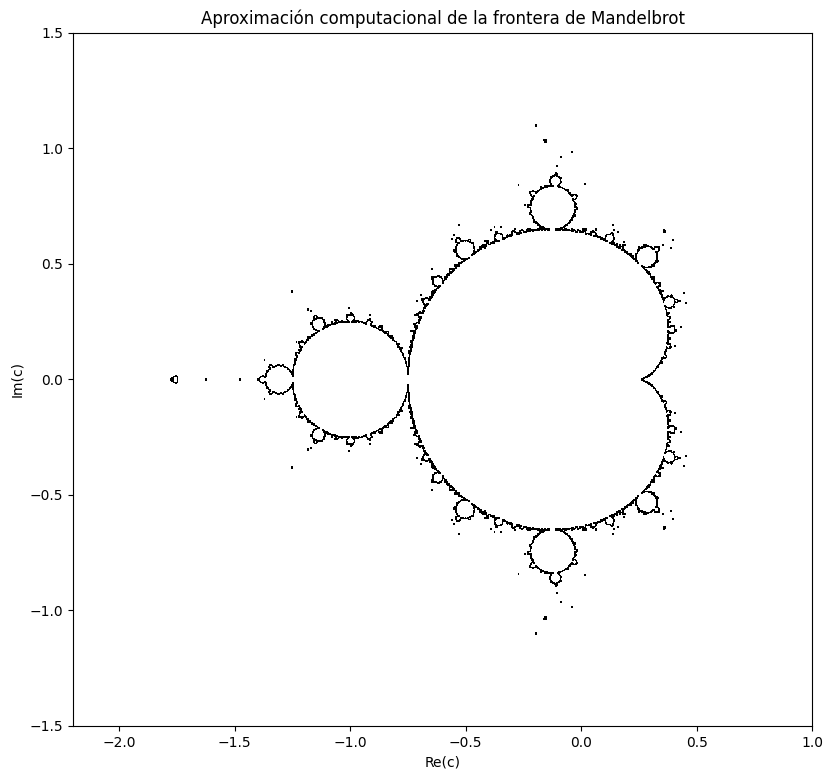

In [ ]:

plt.figure(figsize=(11, 9))

plt.imshow(
    frontera,
    extent=[xmin, xmax, ymin, ymax],
    origin="lower",
    cmap="gray_r",
    interpolation="nearest"
)

plt.xlabel("Re(c)")
plt.ylabel("Im(c)")
plt.title("Aproximación computacional de la frontera de Mandelbrot")

plt.savefig(
    "Figura_3_Frontera_Mandelbrot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

import math
from matplotlib.patches import Rectangle

def contar_cajas(mascara, lado):

    h, w = mascara.shape

    filas = math.ceil(h / lado)
    columnas = math.ceil(w / lado)

    # Completar la matriz para dividirla en bloques
    ampliada = np.zeros(
        (filas * lado, columnas * lado),
        dtype=bool
    )

    ampliada[:h, :w] = mascara

    bloques = ampliada.reshape(
        filas, lado, columnas, lado
    )

    ocupadas = bloques.any(axis=(1, 3))

    return int(ocupadas.sum()), ocupadas


# Diferentes tamaños de cajas
escalas = [4, 8, 16, 32, 64, 128]

conteos = []

for lado in escalas:

    N, ocupadas = contar_cajas(frontera, lado)

    conteos.append(N)

    print("Lado:", lado, "píxeles | Cajas ocupadas:", N)


Lado: 4 píxeles | Cajas ocupadas: 1870
Lado: 8 píxeles | Cajas ocupadas: 749
Lado: 16 píxeles | Cajas ocupadas: 323
Lado: 32 píxeles | Cajas ocupadas: 141
Lado: 64 píxeles | Cajas ocupadas: 61
Lado: 128 píxeles | Cajas ocupadas: 22


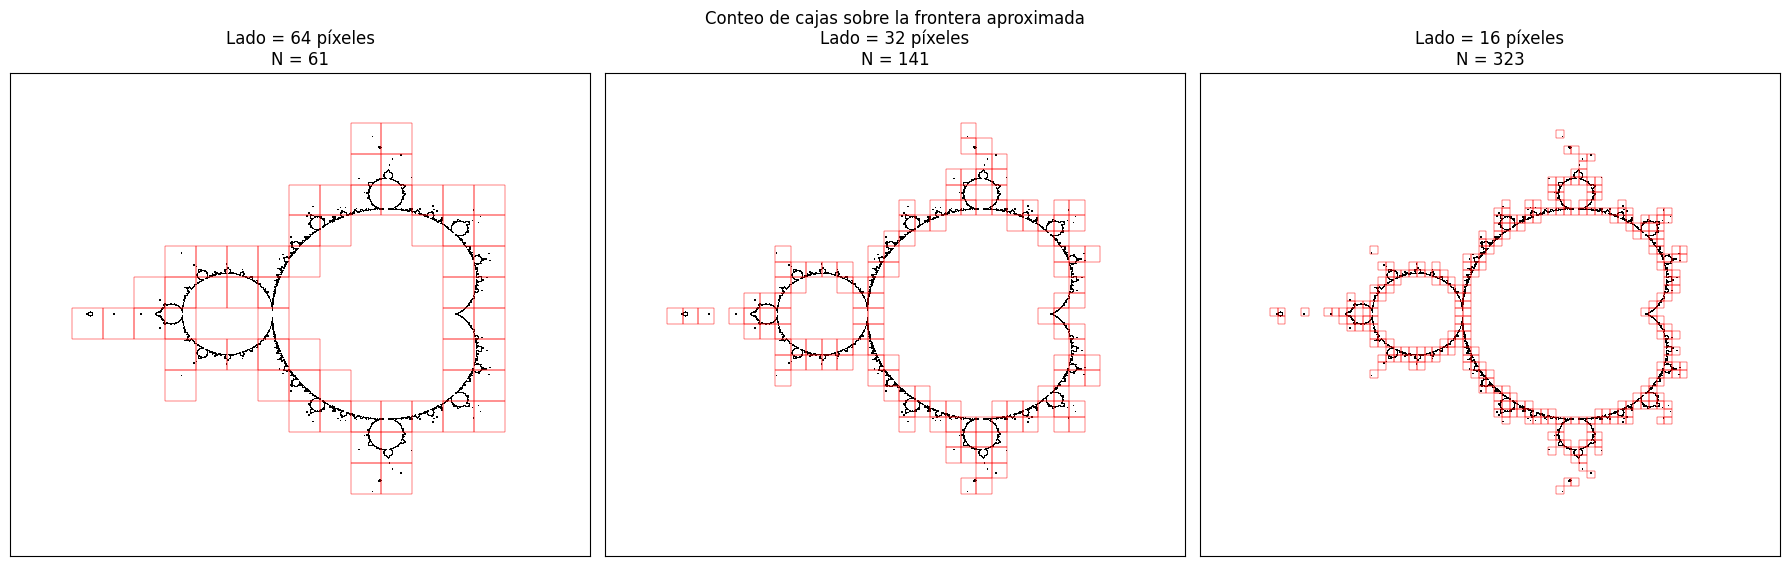

In [ ]:

fig, ejes = plt.subplots(1, 3, figsize=(18, 6))

escalas_visuales = [64, 32, 16]

for ax, lado in zip(ejes, escalas_visuales):

    N, ocupadas = contar_cajas(frontera, lado)

    ax.imshow(
        frontera,
        origin="lower",
        cmap="gray_r",
        interpolation="nearest"
    )

    filas, columnas = ocupadas.shape

    for i in range(filas):
        for j in range(columnas):

            if ocupadas[i, j]:

                ax.add_patch(
                    Rectangle(
                        (j * lado, i * lado),
                        lado,
                        lado,
                        fill=False,
                        edgecolor="red",
                        linewidth=0.35
                    )
                )

    ax.set_title(f"Lado = {lado} píxeles\nN = {N}")
    ax.set_xticks([])
    ax.set_yticks([])

plt.suptitle("Conteo de cajas sobre la frontera aproximada")
plt.tight_layout()

plt.savefig(
    "Figura_4_Box_Counting.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# Convertir el tamaño de caja de píxeles
# a unidades del plano complejo

dx = (xmax - xmin) / (ancho - 1)
dy = (ymax - ymin) / (alto - 1)

# Usaremos el tamaño horizontal de cada píxel
epsilon = np.array(escalas) * dx

N_epsilon = np.array(conteos)

X = np.log(1 / epsilon)
Y = np.log(N_epsilon)

# Ajuste lineal por mínimos cuadrados
pendiente, intercepto = np.polyfit(X, Y, 1)

# Tabla de resultados
tabla = pd.DataFrame({
    "Lado (pixeles)": escalas,
    "epsilon": epsilon,
    "N(epsilon)": N_epsilon,
    "log(1/epsilon)": X,
    "log(N(epsilon))": Y
})

display(tabla)

print("Pendiente estimada:", pendiente)
print("Intercepto:", intercepto)


,Lado (pixeles),epsilon,N(epsilon),log(1/epsilon),log(N(epsilon))
0,4,0.010676,1870,4.539798,7.533694
1,8,0.021351,749,3.846651,6.618739
2,16,0.042702,323,3.153504,5.777652
3,32,0.085405,141,2.460356,4.948760
4,64,0.170809,61,1.767209,4.110874
5,128,0.341618,22,1.074062,3.091042


Pendiente estimada: 1.259915639876321
Intercepto: 1.810298489176481


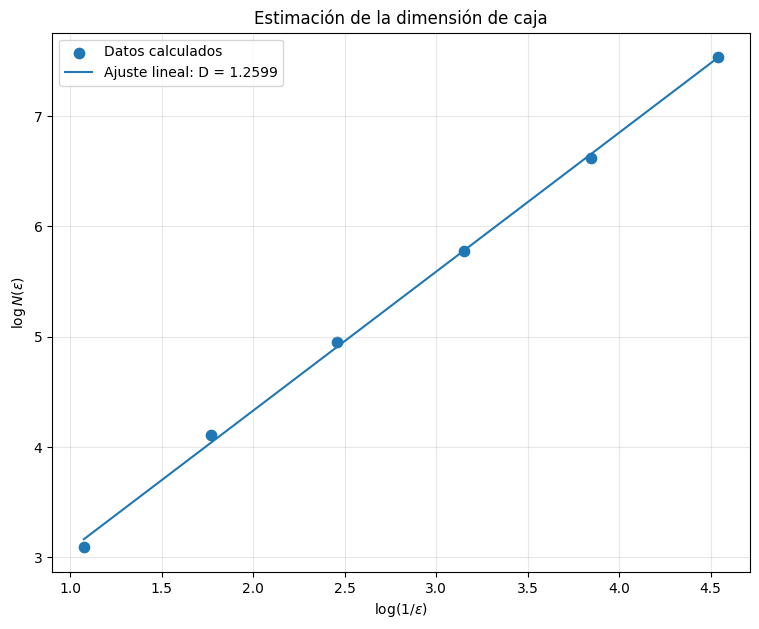

In [ ]:

plt.figure(figsize=(9, 7))

plt.scatter(
    X, Y,
    label="Datos calculados",
    s=55
)

plt.plot(
    X,
    pendiente * X + intercepto,
    label=f"Ajuste lineal: D = {pendiente:.4f}"
)

plt.xlabel(r"$\log(1/\varepsilon)$")
plt.ylabel(r"$\log N(\varepsilon)$")

plt.title("Estimación de la dimensión de caja")
plt.grid(alpha=0.3)
plt.legend()

plt.savefig(
    "Figura_5_Dimension_Box_Counting.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


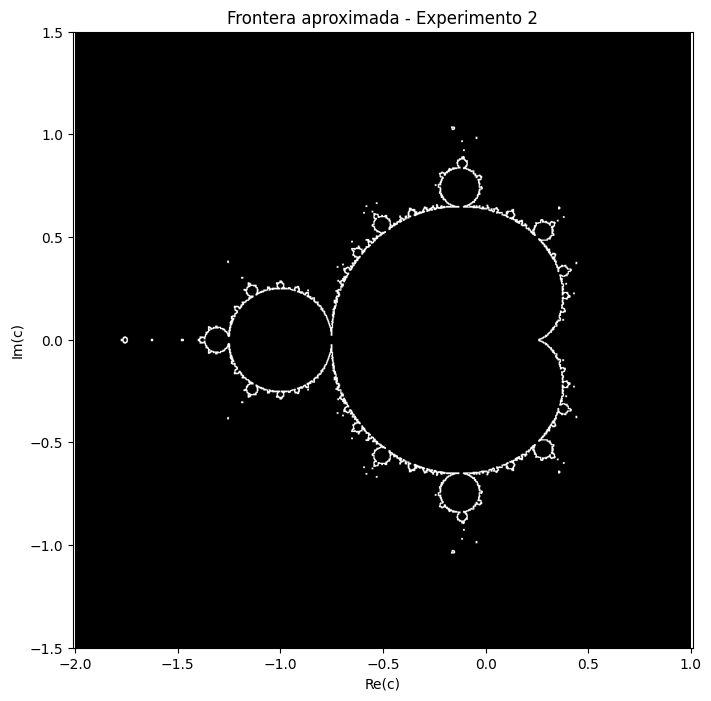

Resolución: 1024 x 1024
Iteraciones máximas: 300


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# EXPERIMENTO 2: CONFIGURACION CORREGIDA
# ==========================================

xmin, xmax = -2.0, 1.0
ymin, ymax = -1.5, 1.5

ancho = 1024
alto = 1024
Nmax = 300

# Crear una malla cuadrada en el plano complejo
x = np.linspace(xmin, xmax, ancho)
y = np.linspace(ymin, ymax, alto)
X, Y = np.meshgrid(x, y)
C = X + 1j * Y

# ==========================================
# CALCULO DEL CONJUNTO DE MANDELBROT
# ==========================================

Z = np.zeros(C.shape, dtype=complex)
iteraciones = np.zeros(C.shape, dtype=int)

activos = np.ones(C.shape, dtype=bool)

for n in range(1, Nmax + 1):
    Z[activos] = Z[activos]**2 + C[activos]

    escaparon = activos & (np.abs(Z) > 2)

    iteraciones[escaparon] = n
    activos[escaparon] = False

# Puntos sin escape detectado
interior_aprox = (iteraciones == 0)

# ==========================================
# EXTRAER LA FRONTERA APROXIMADA
# ==========================================

frontera = np.zeros(interior_aprox.shape, dtype=bool)

# Comparaciones entre vecinos horizontales,
# verticales y diagonales

for dy in [-1, 0, 1]:
    for dx in [-1, 0, 1]:

        if dx == 0 and dy == 0:
            continue

        desplazada = np.roll(
            interior_aprox,
            shift=(dy, dx),
            axis=(0, 1)
        )

        diferencia = interior_aprox != desplazada
        frontera |= diferencia

# Evitar los bordes artificiales de la matriz
frontera[0, :] = False
frontera[-1, :] = False
frontera[:, 0] = False
frontera[:, -1] = False

# ==========================================
# VISUALIZAR LA FRONTERA
# ==========================================

plt.figure(figsize=(8, 8))
plt.imshow(
    frontera,
    extent=[xmin, xmax, ymin, ymax],
    origin="lower",
    cmap="gray"
)
plt.xlabel("Re(c)")
plt.ylabel("Im(c)")
plt.title("Frontera aproximada - Experimento 2")
plt.axis("equal")
plt.show()

print("Resolución:", ancho, "x", alto)
print("Iteraciones máximas:", Nmax)


In [ ]:

# ==========================================
# BOX COUNTING - EXPERIMENTO 2
# ==========================================

escalas_2 = [4, 8, 16, 32, 64, 128]

conteos_2 = []

for lado in escalas_2:

    cajas = frontera.reshape(
        alto // lado, lado,
        ancho // lado, lado
    )

    ocupadas = np.any(cajas, axis=(1, 3))

    conteos_2.append(np.sum(ocupadas))

# Tamaño real de cada píxel en el plano complejo
delta = (xmax - xmin) / ancho

epsilon_2 = np.array(escalas_2) * delta
N_epsilon_2 = np.array(conteos_2)

log_inverso_2 = np.log(1 / epsilon_2)
log_conteos_2 = np.log(N_epsilon_2)

# Ajuste lineal
pendiente_2, intercepto_2 = np.polyfit(
    log_inverso_2,
    log_conteos_2,
    1
)

# Tabla de resultados
tabla_2 = pd.DataFrame({
    "Lado (pixeles)": escalas_2,
    "epsilon": epsilon_2,
    "N(epsilon)": N_epsilon_2,
    "log(1/epsilon)": log_inverso_2,
    "log(N(epsilon))": log_conteos_2
})

display(tabla_2)

print("Pendiente estimada:", pendiente_2)
print("Intercepto:", intercepto_2)


,Lado (pixeles),epsilon,N(epsilon),log(1/epsilon),log(N(epsilon))
0,4,0.011719,1672,4.446565,7.421776
1,8,0.023438,670,3.753418,6.507278
2,16,0.046875,292,3.060271,5.676754
3,32,0.093750,130,2.367124,4.867534
4,64,0.187500,56,1.673976,4.025352
5,128,0.375000,24,0.980829,3.178054


Pendiente estimada: 1.2148979140717944
Intercepto: 1.9825928069106715


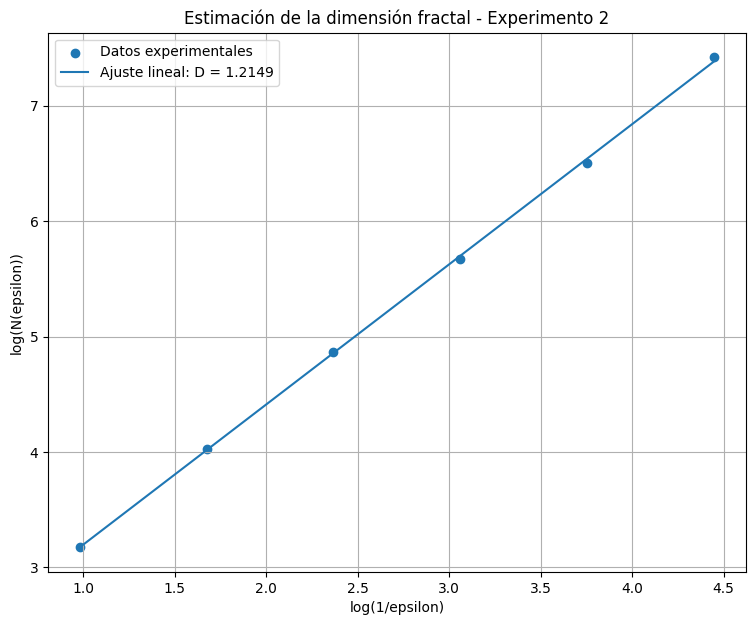

In [ ]:

plt.figure(figsize=(9, 7))

plt.scatter(
    log_inverso_2,
    log_conteos_2,
    label="Datos experimentales"
)

ajuste = pendiente_2 * log_inverso_2 + intercepto_2

plt.plot(
    log_inverso_2,
    ajuste,
    label=f"Ajuste lineal: D = {pendiente_2:.4f}"
)

plt.xlabel("log(1/epsilon)")
plt.ylabel("log(N(epsilon))")
plt.title("Estimación de la dimensión fractal - Experimento 2")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:
import pandas as pd

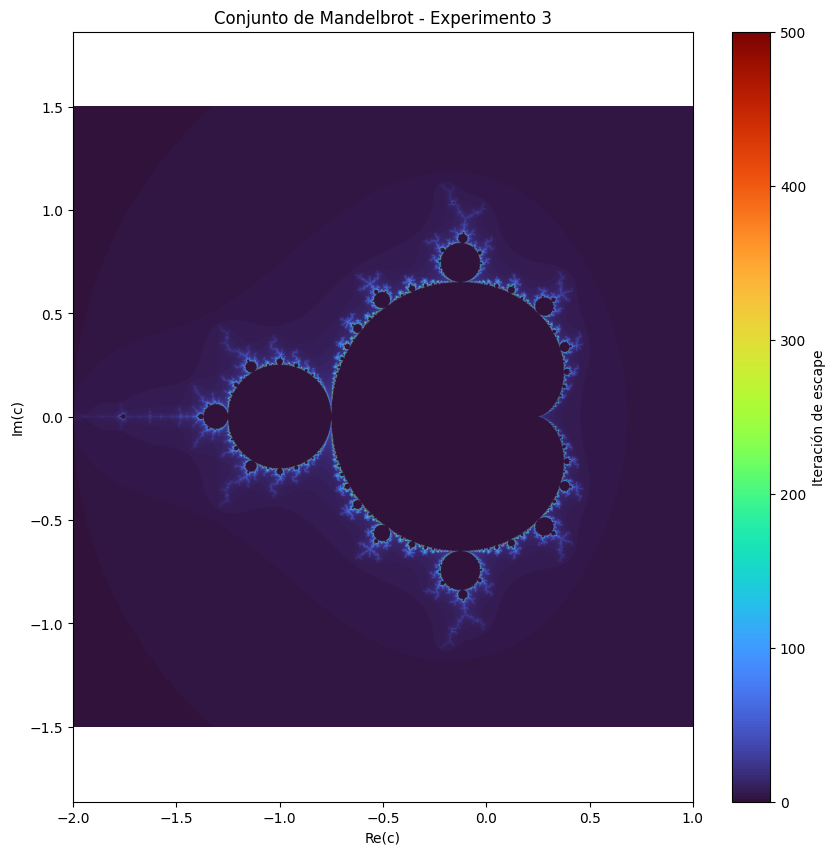

Resolución: 2048 x 2048
Iteraciones máximas: 500


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# ==========================================
# EXPERIMENTO 3
# ==========================================

xmin, xmax = -2.0, 1.0
ymin, ymax = -1.5, 1.5

ancho = 2048
alto = 2048
Nmax = 500

# Crear la malla del plano complejo
x = np.linspace(xmin, xmax, ancho)
y = np.linspace(ymin, ymax, alto)

X, Y = np.meshgrid(x, y)
C = X + 1j * Y

# Inicializar iteraciones
Z = np.zeros(C.shape, dtype=complex)
iteraciones_3 = np.zeros(C.shape, dtype=np.int32)

activos = np.ones(C.shape, dtype=bool)

# Algoritmo de escape
for n in range(1, Nmax + 1):

    Z[activos] = Z[activos]**2 + C[activos]

    escaparon = activos & (np.abs(Z) > 2)

    iteraciones_3[escaparon] = n
    activos[escaparon] = False

# Clasificación aproximada
interior_3 = (iteraciones_3 == 0)

# Visualización
plt.figure(figsize=(10, 10))

plt.imshow(
    iteraciones_3,
    extent=[xmin, xmax, ymin, ymax],
    origin="lower",
    cmap="turbo"
)

plt.colorbar(label="Iteración de escape")
plt.xlabel("Re(c)")
plt.ylabel("Im(c)")
plt.title("Conjunto de Mandelbrot - Experimento 3")
plt.axis("equal")
plt.show()

print("Resolución:", ancho, "x", alto)
print("Iteraciones máximas:", Nmax)


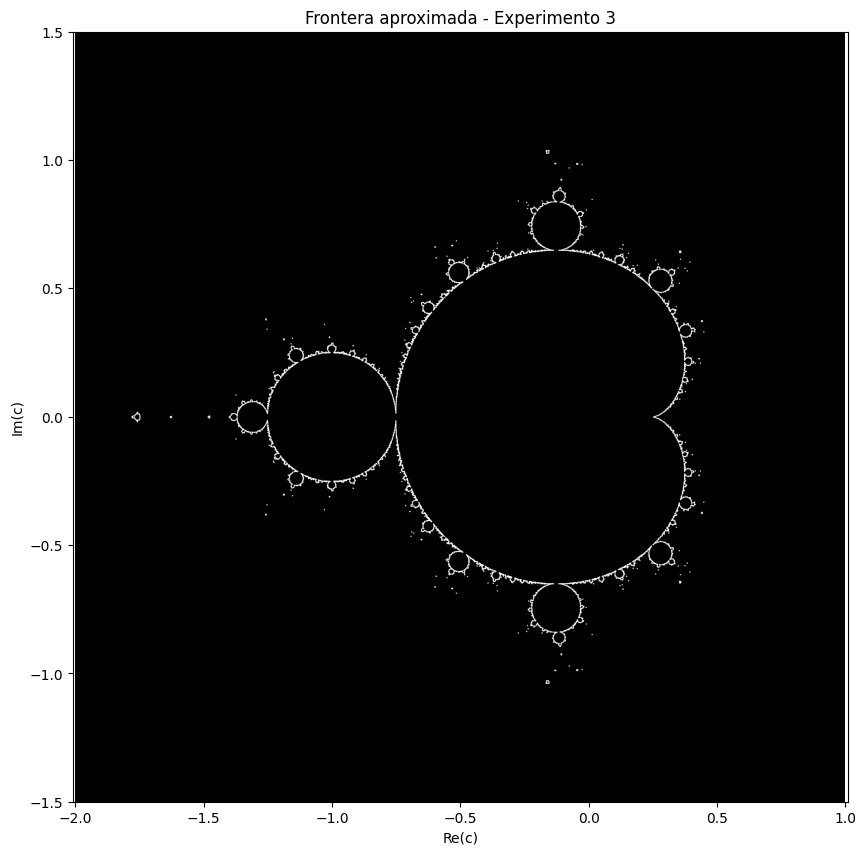

In [ ]:

# ==========================================
# EXTRACCIÓN DE LA FRONTERA
# ==========================================

frontera_3 = np.zeros(interior_3.shape, dtype=bool)

for dy in [-1, 0, 1]:
    for dx in [-1, 0, 1]:

        if dx == 0 and dy == 0:
            continue

        desplazada = np.roll(
            interior_3,
            shift=(dy, dx),
            axis=(0, 1)
        )

        diferencia = interior_3 != desplazada
        frontera_3 |= diferencia

# Eliminar bordes artificiales
frontera_3[0, :] = False
frontera_3[-1, :] = False
frontera_3[:, 0] = False
frontera_3[:, -1] = False

# Visualizar
plt.figure(figsize=(10, 10))

plt.imshow(
    frontera_3,
    extent=[xmin, xmax, ymin, ymax],
    origin="lower",
    cmap="gray"
)

plt.xlabel("Re(c)")
plt.ylabel("Im(c)")
plt.title("Frontera aproximada - Experimento 3")
plt.axis("equal")
plt.show()


In [ ]:

# ==========================================
# BOX COUNTING - EXPERIMENTO 3
# ==========================================

escalas_3 = [4, 8, 16, 32, 64, 128, 256]

conteos_3 = []

for lado in escalas_3:

    cajas = frontera_3.reshape(
        alto // lado, lado,
        ancho // lado, lado
    )

    ocupadas = np.any(cajas, axis=(1, 3))

    conteos_3.append(np.sum(ocupadas))

# Tamaño del píxel en el plano complejo
delta_3 = (xmax - xmin) / (ancho - 1)

epsilon_3 = np.array(escalas_3) * delta_3
N_epsilon_3 = np.array(conteos_3)

log_inverso_3 = np.log(1 / epsilon_3)
log_conteos_3 = np.log(N_epsilon_3)

# Ajuste lineal
pendiente_3, intercepto_3 = np.polyfit(
    log_inverso_3,
    log_conteos_3,
    1
)

# Tabla de resultados
tabla_3 = pd.DataFrame({
    "Lado (pixeles)": escalas_3,
    "epsilon": epsilon_3,
    "N(epsilon)": N_epsilon_3,
    "log(1/epsilon)": log_inverso_3,
    "log(N(epsilon))": log_conteos_3
})

display(tabla_3)

print("Pendiente estimada:", pendiente_3)
print("Intercepto:", intercepto_3)


,Lado (pixeles),epsilon,N(epsilon),log(1/epsilon),log(N(epsilon))
0,4,0.005862,4182,5.139224,8.338545
1,8,0.011724,1718,4.446077,7.448916
2,16,0.023449,722,3.752930,6.582025
3,32,0.046898,332,3.059782,5.805135
4,64,0.093796,152,2.366635,5.023881
5,128,0.187592,60,1.673488,4.094345
6,256,0.375183,24,0.980341,3.178054


Pendiente estimada: 1.2236506965038842
Intercepto: 2.0374522855889183


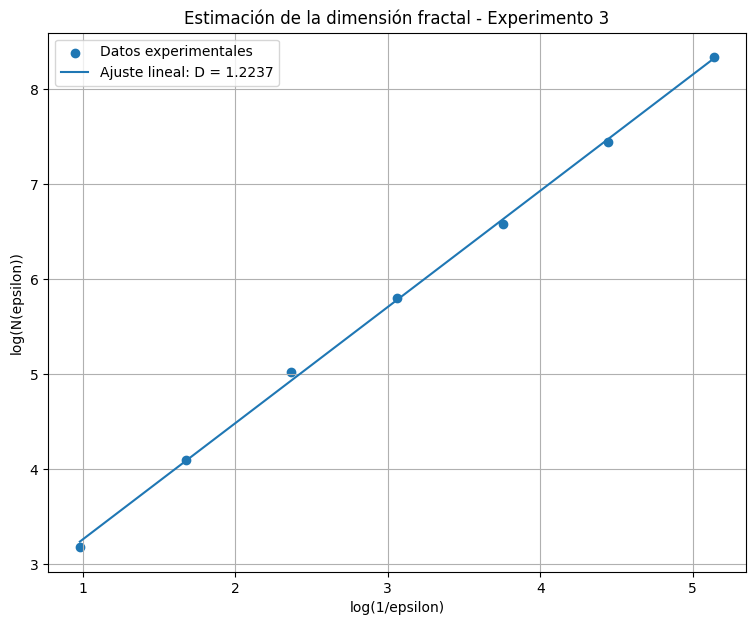

In [ ]:

plt.figure(figsize=(9, 7))

plt.scatter(
    log_inverso_3,
    log_conteos_3,
    label="Datos experimentales"
)

ajuste_3 = (
    pendiente_3 * log_inverso_3 + intercepto_3
)

plt.plot(
    log_inverso_3,
    ajuste_3,
    label=f"Ajuste lineal: D = {pendiente_3:.4f}"
)

plt.xlabel("log(1/epsilon)")
plt.ylabel("log(N(epsilon))")
plt.title("Estimación de la dimensión fractal - Experimento 3")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# ==========================================
# ANALISIS DE ESTABILIDAD - EXPERIMENTO 3
# ==========================================

# Ajuste lineal global
ajuste_3 = pendiente_3 * log_inverso_3 + intercepto_3

# Coeficiente de determinacion R^2
residuos = log_conteos_3 - ajuste_3

SSE = np.sum(residuos**2)
SST = np.sum((log_conteos_3 - np.mean(log_conteos_3))**2)

R2 = 1 - SSE / SST

print("Pendiente global:", pendiente_3)
print("Coeficiente R²:", R2)

# Pendientes entre escalas consecutivas
pendientes_locales = (
    np.diff(log_conteos_3) /
    np.diff(log_inverso_3)
)

tabla_local = pd.DataFrame({
    "Escala inicial": escalas_3[:-1],
    "Escala siguiente": escalas_3[1:],
    "Pendiente local": pendientes_locales
})

display(tabla_local)

Pendiente global: 1.2236506965038842
Coeficiente R²: 0.999227149329167


,Escala inicial,Escala siguiente,Pendiente local
0,4,8,1.283463
1,8,16,1.250659
2,16,32,1.120816
3,32,64,1.127112
4,64,128,1.341037
5,128,256,1.321928


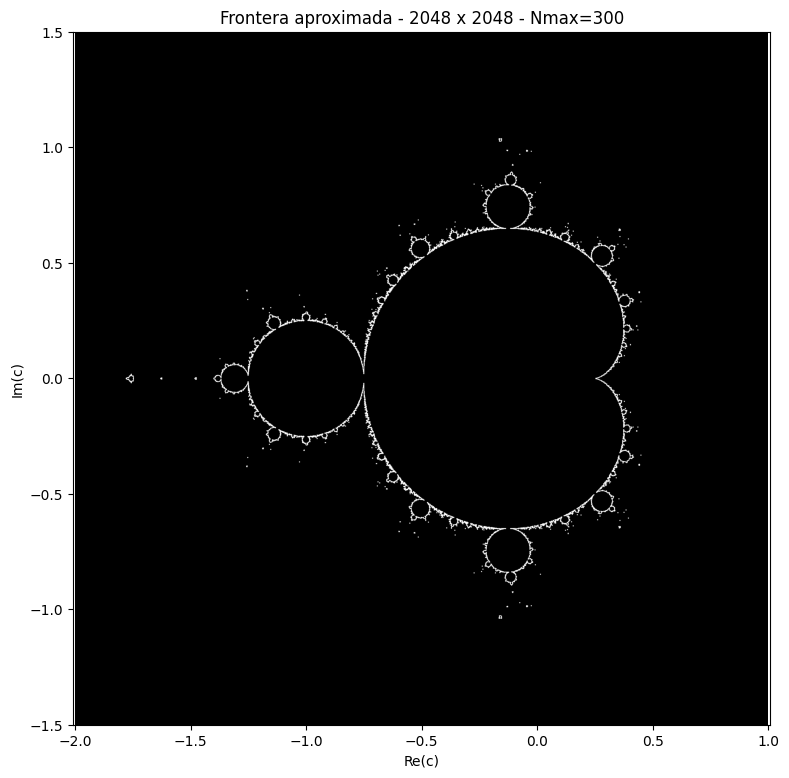

In [ ]:

# ==========================================
# EXPERIMENTO 4
# Misma resolución, diferente Nmax
# ==========================================

Nmax_4 = 300

Z_4 = np.zeros(C.shape, dtype=complex)
iteraciones_4 = np.zeros(C.shape, dtype=np.int32)

activos_4 = np.ones(C.shape, dtype=bool)

for n in range(1, Nmax_4 + 1):

    Z_4[activos_4] = Z_4[activos_4]**2 + C[activos_4]

    escaparon_4 = activos_4 & (np.abs(Z_4) > 2)

    iteraciones_4[escaparon_4] = n
    activos_4[escaparon_4] = False

interior_4 = (iteraciones_4 == 0)

# Extraer frontera
frontera_4 = np.zeros(interior_4.shape, dtype=bool)

for dy in [-1, 0, 1]:
    for dx in [-1, 0, 1]:

        if dx == 0 and dy == 0:
            continue

        desplazada = np.roll(
            interior_4,
            shift=(dy, dx),
            axis=(0, 1)
        )

        frontera_4 |= (interior_4 != desplazada)

frontera_4[0, :] = False
frontera_4[-1, :] = False
frontera_4[:, 0] = False
frontera_4[:, -1] = False

# Visualización
plt.figure(figsize=(9, 9))

plt.imshow(
    frontera_4,
    extent=[xmin, xmax, ymin, ymax],
    origin="lower",
    cmap="gray"
)

plt.title("Frontera aproximada - 2048 x 2048 - Nmax=300")
plt.xlabel("Re(c)")
plt.ylabel("Im(c)")
plt.axis("equal")
plt.show()


In [ ]:

# ==========================================
# BOX COUNTING - Nmax 300
# ==========================================

escalas_4 = [4, 8, 16, 32, 64, 128, 256]

conteos_4 = []

for lado in escalas_4:

    cajas = frontera_4.reshape(
        alto // lado, lado,
        ancho // lado, lado
    )

    ocupadas = np.any(cajas, axis=(1, 3))
    conteos_4.append(np.sum(ocupadas))

delta_4 = (xmax - xmin) / (ancho - 1)

epsilon_4 = np.array(escalas_4) * delta_4
N_epsilon_4 = np.array(conteos_4)

log_inverso_4 = np.log(1 / epsilon_4)
log_conteos_4 = np.log(N_epsilon_4)

pendiente_4, intercepto_4 = np.polyfit(
    log_inverso_4,
    log_conteos_4,
    1
)

ajuste_4 = pendiente_4 * log_inverso_4 + intercepto_4

R2_4 = 1 - (
    np.sum((log_conteos_4 - ajuste_4)**2) /
    np.sum((log_conteos_4 - np.mean(log_conteos_4))**2)
)

tabla_4 = pd.DataFrame({
    "Lado (pixeles)": escalas_4,
    "N(epsilon)": N_epsilon_4,
    "log(1/epsilon)": log_inverso_4,
    "log(N(epsilon))": log_conteos_4
})

display(tabla_4)

print("Pendiente con 300 iteraciones:", pendiente_4)
print("R²:", R2_4)


,Lado (pixeles),N(epsilon),log(1/epsilon),log(N(epsilon))
0,4,4448,5.139224,8.400210
1,8,1764,4.446077,7.475339
2,16,730,3.752930,6.593045
3,32,332,3.059782,5.805135
4,64,152,2.366635,5.023881
5,128,60,1.673488,4.094345
6,256,24,0.980341,3.178054


Pendiente con 300 iteraciones: 1.2364731912938878
R²: 0.999244870998431


In [ ]:

# ==========================================
# COMPARACIÓN: 300 Y 500 ITERACIONES
# ==========================================

comparacion_iteraciones = pd.DataFrame({
    "Lado (pixeles)": escalas_3,
    "N(epsilon), 300": conteos_4,
    "N(epsilon), 500": conteos_3
})

display(comparacion_iteraciones)

print("Pendiente Nmax=300:", pendiente_4)
print("Pendiente Nmax=500:", pendiente_3)
print("Diferencia:", abs(pendiente_4 - pendiente_3))


,Lado (pixeles),"N(epsilon), 300","N(epsilon), 500"
0,4,4448,4182
1,8,1764,1718
2,16,730,722
3,32,332,332
4,64,152,152
5,128,60,60
6,256,24,24


Pendiente Nmax=300: 1.2364731912938878
Pendiente Nmax=500: 1.2236506965038842
Diferencia: 0.012822494790003525


Calculando malla 100 x 100...
Calculando malla 200 x 200...
Calculando malla 400 x 400...
Calculando malla 800 x 800...

Experimentos completados.


,Resolucion,Puntos totales,Puntos escapados,Puntos no escapados,h_x,h_y,Epsilon malla,% no escapados,Tiempo (s)
0,100 x 100,10000,8340,1660,0.030303,0.030303,0.021427,16.600000,0.041339
1,200 x 200,40000,33346,6654,0.015075,0.015075,0.010660,16.635000,0.181333
2,400 x 400,160000,133221,26779,0.007519,0.007519,0.005317,16.736875,0.766429
3,800 x 800,640000,532537,107463,0.003755,0.003755,0.002655,16.791094,5.938021


/tmp/ipykernel_813/2962243200.py:201: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


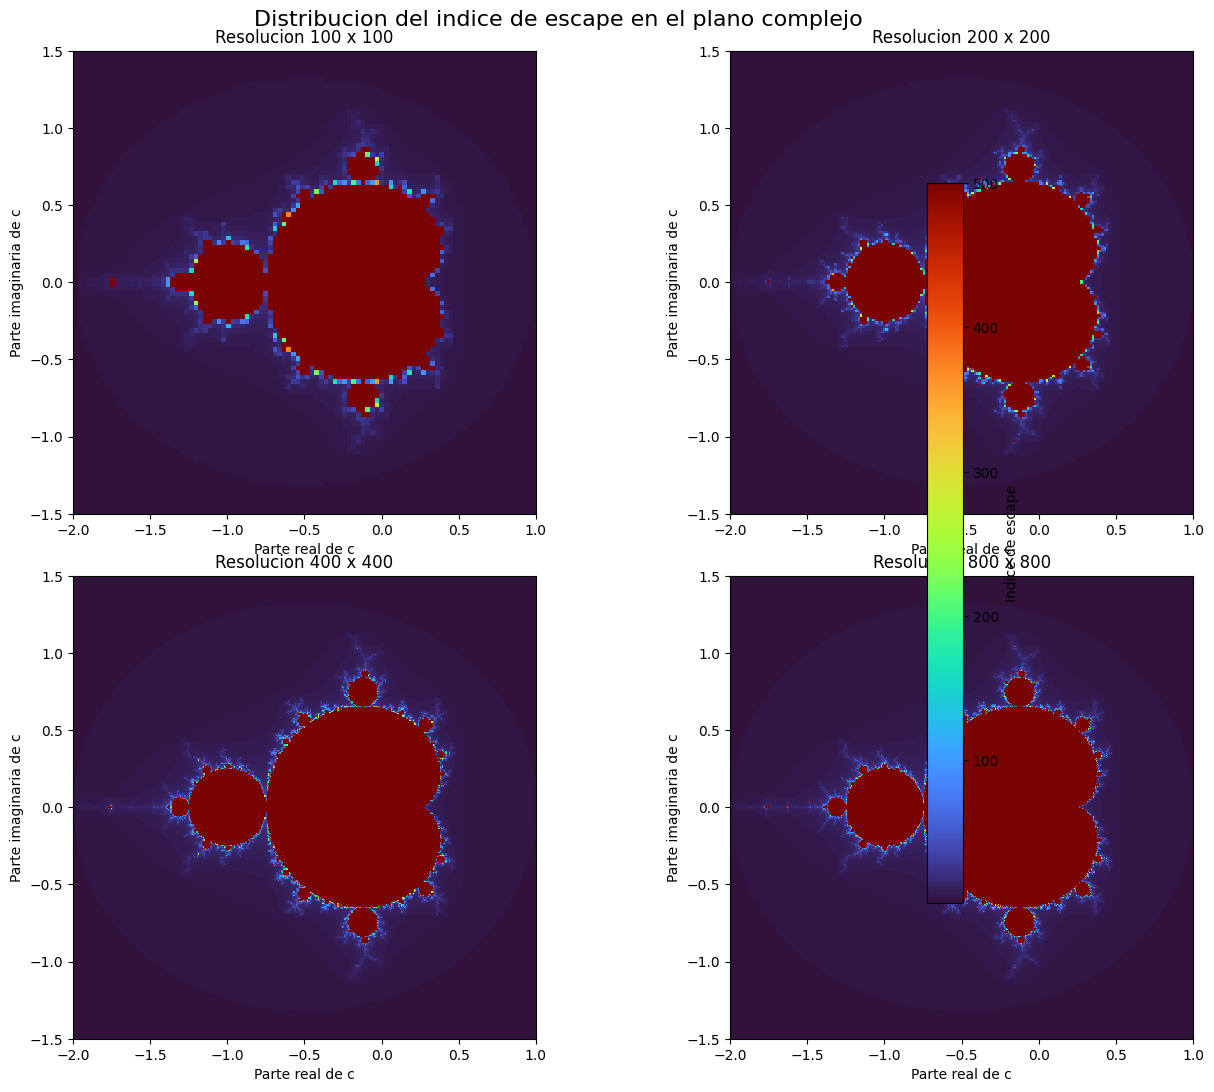

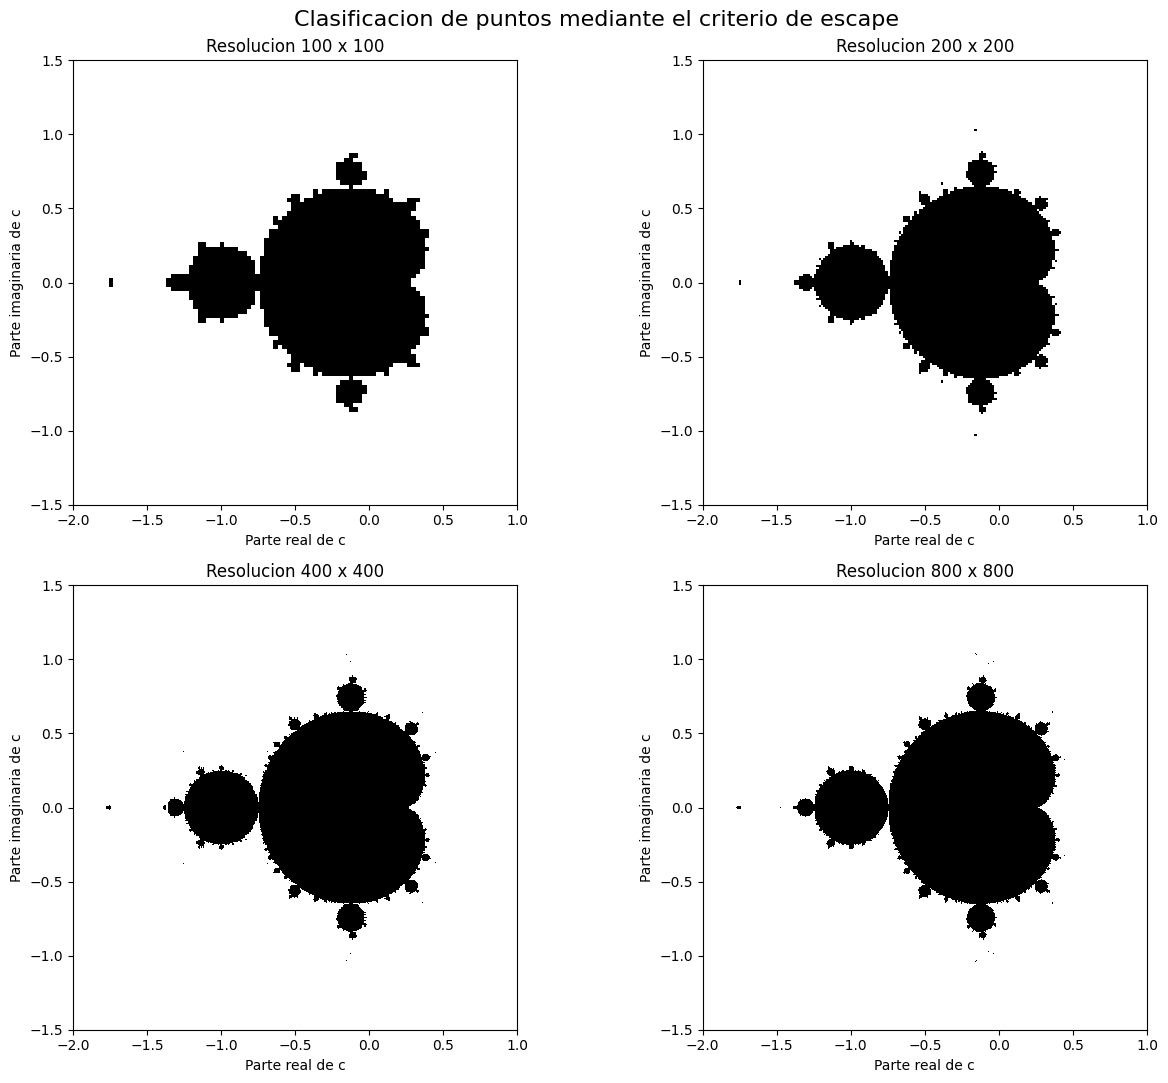

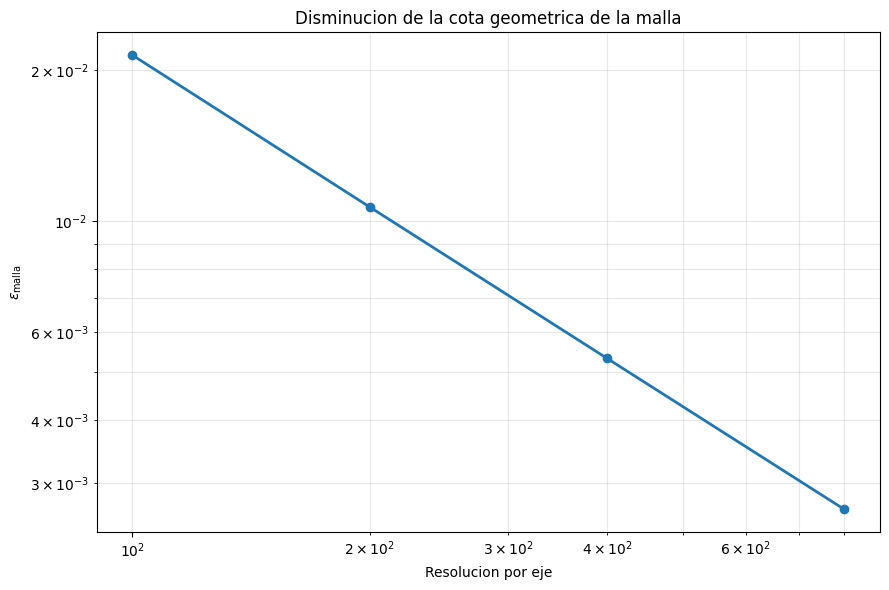

RESUMEN DEL EXPERIMENTO
-----------------------
Dominio real: -2.0 a 1.0
Dominio imaginario: -1.5 a 1.5
Maximo de iteraciones: 500
Radio de escape: 2.0

Resolucion: 100 x 100
Puntos no escapados: 1660
Epsilon geometrico de la malla: 0.02142747821777417

Resolucion: 200 x 200
Puntos no escapados: 6654
Epsilon geometrico de la malla: 0.010659901223917802

Resolucion: 400 x 400
Puntos no escapados: 26779
Epsilon geometrico de la malla: 0.005316592339748478

Resolucion: 800 x 800
Puntos no escapados: 107463
Epsilon geometrico de la malla: 0.0026549691408756476


In [ ]:

# ============================================================
# SEMINARIO: DIMENSION FRACTAL DEL CONJUNTO DE MANDELBROT
# EXPERIMENTO 1: CONSTRUCCION DE LA MALLA Y CRITERIO DE ESCAPE
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# ------------------------------------------------------------
# 1. PARAMETROS DEL EXPERIMENTO
# ------------------------------------------------------------

xmin, xmax = -2.0, 1.0
ymin, ymax = -1.5, 1.5

Nmax = 500
radio_escape = 2.0

resoluciones = [100, 200, 400, 800]

# ------------------------------------------------------------
# 2. FUNCION PARA CONSTRUIR LA MALLA Y CLASIFICAR LOS PUNTOS
# ------------------------------------------------------------

def construir_mandelbrot(resolucion, Nmax=500):

    inicio = time.time()

    # Coordenadas del plano complejo
    x = np.linspace(xmin, xmax, resolucion)
    y = np.linspace(ymin, ymax, resolucion)

    X, Y = np.meshgrid(x, y)
    C = X + 1j * Y

    # Condicion inicial
    Z = np.zeros(C.shape, dtype=np.complex128)

    # Registro de escape
    escape = np.zeros(C.shape, dtype=bool)

    # Tiempo de escape
    tiempo_escape = np.full(
        C.shape,
        Nmax,
        dtype=np.int32
    )

    # Iteracion de Mandelbrot
    for n in range(1, Nmax + 1):

        activos = ~escape

        Z[activos] = (
            Z[activos]**2 + C[activos]
        )

        nuevos_escapes = (
            activos & (np.abs(Z) > radio_escape)
        )

        tiempo_escape[nuevos_escapes] = n

        escape |= nuevos_escapes

        if np.all(escape):
            break

    # Puntos que no escaparon dentro de Nmax
    no_escapados = ~escape

    # Separacion de la malla
    hx = (xmax - xmin) / (resolucion - 1)
    hy = (ymax - ymin) / (resolucion - 1)

    # Cota geometrica de cobertura de la malla
    epsilon_malla = 0.5 * np.sqrt(hx**2 + hy**2)

    # Estadisticas
    total_puntos = resolucion**2
    cantidad_escapados = np.count_nonzero(escape)
    cantidad_no_escapados = np.count_nonzero(no_escapados)

    porcentaje_escapados = (
        100 * cantidad_escapados / total_puntos
    )

    porcentaje_no_escapados = (
        100 * cantidad_no_escapados / total_puntos
    )

    tiempo_calculo = time.time() - inicio

    return {
        "resolucion": resolucion,
        "X": X,
        "Y": Y,
        "escape": escape,
        "no_escapados": no_escapados,
        "tiempo_escape": tiempo_escape,
        "hx": hx,
        "hy": hy,
        "epsilon_malla": epsilon_malla,
        "total_puntos": total_puntos,
        "cantidad_escapados": cantidad_escapados,
        "cantidad_no_escapados": cantidad_no_escapados,
        "porcentaje_escapados": porcentaje_escapados,
        "porcentaje_no_escapados": porcentaje_no_escapados,
        "tiempo_calculo": tiempo_calculo
    }


# ------------------------------------------------------------
# 3. EJECUCION PARA LAS DIFERENTES RESOLUCIONES
# ------------------------------------------------------------

resultados = {}

for resolucion in resoluciones:

    print(f"Calculando malla {resolucion} x {resolucion}...")

    resultados[resolucion] = construir_mandelbrot(
        resolucion,
        Nmax
    )

print("\nExperimentos completados.")


# ------------------------------------------------------------
# 4. TABLA DE RESULTADOS
# ------------------------------------------------------------

filas = []

for resolucion, R in resultados.items():

    filas.append({
        "Resolucion": f"{resolucion} x {resolucion}",
        "Puntos totales": R["total_puntos"],
        "Puntos escapados": R["cantidad_escapados"],
        "Puntos no escapados": R["cantidad_no_escapados"],
        "h_x": R["hx"],
        "h_y": R["hy"],
        "Epsilon malla": R["epsilon_malla"],
        "% no escapados": R["porcentaje_no_escapados"],
        "Tiempo (s)": R["tiempo_calculo"]
    })

tabla_resultados = pd.DataFrame(filas)

display(tabla_resultados.round(6))


# ------------------------------------------------------------
# 5. FIGURA 1: TIEMPO DE ESCAPE
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 11)
)

axes = axes.flatten()

for ax, resolucion in zip(axes, resoluciones):

    R = resultados[resolucion]

    imagen = ax.imshow(
        R["tiempo_escape"],
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap="turbo",
        interpolation="nearest",
        aspect="equal"
    )

    ax.set_title(
        f"Resolucion {resolucion} x {resolucion}"
    )

    ax.set_xlabel("Parte real de c")
    ax.set_ylabel("Parte imaginaria de c")

fig.colorbar(
    imagen,
    ax=axes.tolist(),
    label="Indice de escape",
    shrink=0.85
)

fig.suptitle(
    "Distribucion del indice de escape en el plano complejo",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "experimento_1_tiempo_escape.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 6. FIGURA 2: CLASIFICACION DE LOS PUNTOS
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2, 2,
    figsize=(13, 11)
)

axes = axes.flatten()

for ax, resolucion in zip(axes, resoluciones):

    R = resultados[resolucion]

    ax.imshow(
        R["no_escapados"],
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap="gray_r",
        interpolation="nearest",
        aspect="equal",
        vmin=0,
        vmax=1
    )

    ax.set_title(
        f"Resolucion {resolucion} x {resolucion}"
    )

    ax.set_xlabel("Parte real de c")
    ax.set_ylabel("Parte imaginaria de c")

fig.suptitle(
    "Clasificacion de puntos mediante el criterio de escape",
    fontsize=16
)

plt.tight_layout()
plt.savefig(
    "experimento_2_clasificacion.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 7. FIGURA 3: EVOLUCION DEL ERROR GEOMETRICO DE LA MALLA
# ------------------------------------------------------------

resoluciones_x = np.array(resoluciones)

epsilons = np.array([
    resultados[r]["epsilon_malla"]
    for r in resoluciones
])

fig, ax = plt.subplots(figsize=(9, 6))

ax.loglog(
    resoluciones_x,
    epsilons,
    marker="o",
    linewidth=2
)

ax.set_title(
    "Disminucion de la cota geometrica de la malla"
)

ax.set_xlabel("Resolucion por eje")
ax.set_ylabel(r"$\varepsilon_{\mathrm{malla}}$")

ax.grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.savefig(
    "experimento_3_refinamiento_malla.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# ------------------------------------------------------------
# 8. RESUMEN DE LA PRIMERA ETAPA
# ------------------------------------------------------------

print("RESUMEN DEL EXPERIMENTO")
print("-----------------------")
print("Dominio real:", xmin, "a", xmax)
print("Dominio imaginario:", ymin, "a", ymax)
print("Maximo de iteraciones:", Nmax)
print("Radio de escape:", radio_escape)

for resolucion, R in resultados.items():

    print("\nResolucion:", resolucion, "x", resolucion)

    print(
        "Puntos no escapados:",
        R["cantidad_no_escapados"]
    )

    print(
        "Epsilon geometrico de la malla:",
        R["epsilon_malla"]
    )


COMPARACIÓN ENTRE APROXIMACIONES


,Comparación,Diferencia relativa,Índice de Jaccard,Distancia de Hausdorff aproximada
0,100 → 200,0.007850,0.953851,0.168548
1,200 → 400,0.004681,0.972333,0.149244
2,400 → 800,0.003130,0.981504,0.123905


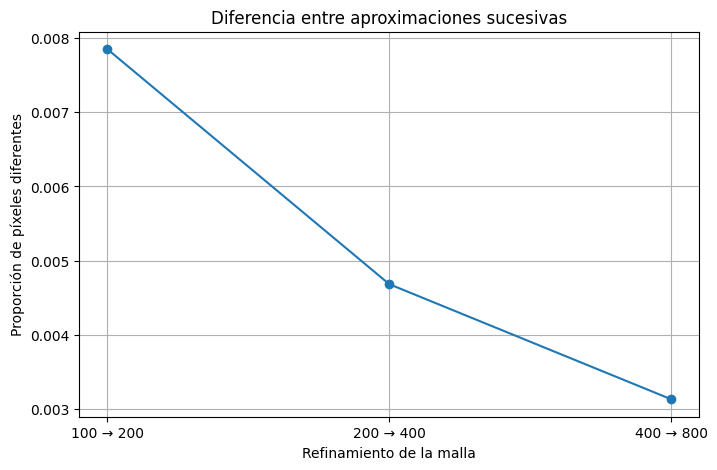

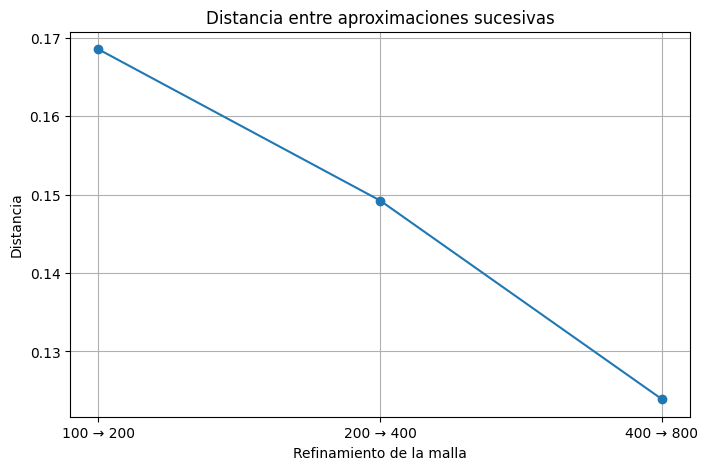

In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import map_coordinates, distance_transform_edt

# Resoluciones ya calculadas
resoluciones = sorted(resultados.keys())

comparaciones = []

for i in range(len(resoluciones) - 1):

    r1 = resoluciones[i]
    r2 = resoluciones[i + 1]

    M1 = resultados[r1]["no_escapados"]
    M2 = resultados[r2]["no_escapados"]

    n1 = M1.shape[0]
    n2 = M2.shape[0]

    # Llevamos la malla gruesa a las dimensiones
    # de la malla más fina mediante vecino más cercano.
    filas = np.linspace(0, n1 - 1, n2)
    columnas = np.linspace(0, n1 - 1, n2)

    F, C = np.meshgrid(filas, columnas, indexing="ij")

    M1_ampliada = map_coordinates(
        M1.astype(float),
        [F, C],
        order=0,
        mode="nearest"
    ) > 0.5

    M2 = M2.astype(bool)

    # Diferencia entre las dos aproximaciones
    diferencia = np.logical_xor(M1_ampliada, M2)

    proporcion_diferente = np.mean(diferencia)

    # Índice de Jaccard
    interseccion = np.logical_and(M1_ampliada, M2).sum()
    union = np.logical_or(M1_ampliada, M2).sum()

    jaccard = interseccion / union if union != 0 else 1

    # Distancia física entre puntos de las aproximaciones
    dx = 3 / (n2 - 1)
    dy = 3 / (n2 - 1)

    distancia_M1 = distance_transform_edt(
        ~M1_ampliada,
        sampling=(dy, dx)
    )

    distancia_M2 = distance_transform_edt(
        ~M2,
        sampling=(dy, dx)
    )

    d12 = distancia_M2[M1_ampliada].max() if M1_ampliada.any() else 0
    d21 = distancia_M1[M2].max() if M2.any() else 0

    hausdorff_aprox = max(d12, d21)

    comparaciones.append({
        "Comparación": f"{r1} → {r2}",
        "Diferencia relativa": proporcion_diferente,
        "Índice de Jaccard": jaccard,
        "Distancia de Hausdorff aproximada": hausdorff_aprox
    })

tabla_comparaciones = pd.DataFrame(comparaciones)

print("COMPARACIÓN ENTRE APROXIMACIONES")
display(tabla_comparaciones)

# Gráfica de la diferencia relativa
plt.figure(figsize=(8, 5))

plt.plot(
    tabla_comparaciones["Comparación"],
    tabla_comparaciones["Diferencia relativa"],
    marker="o"
)

plt.xlabel("Refinamiento de la malla")
plt.ylabel("Proporción de píxeles diferentes")
plt.title("Diferencia entre aproximaciones sucesivas")
plt.grid(True)
plt.show()

# Gráfica de la distancia de Hausdorff aproximada
plt.figure(figsize=(8, 5))

plt.plot(
    tabla_comparaciones["Comparación"],
    tabla_comparaciones["Distancia de Hausdorff aproximada"],
    marker="o"
)

plt.xlabel("Refinamiento de la malla")
plt.ylabel("Distancia")
plt.title("Distancia entre aproximaciones sucesivas")
plt.grid(True)
plt.show()


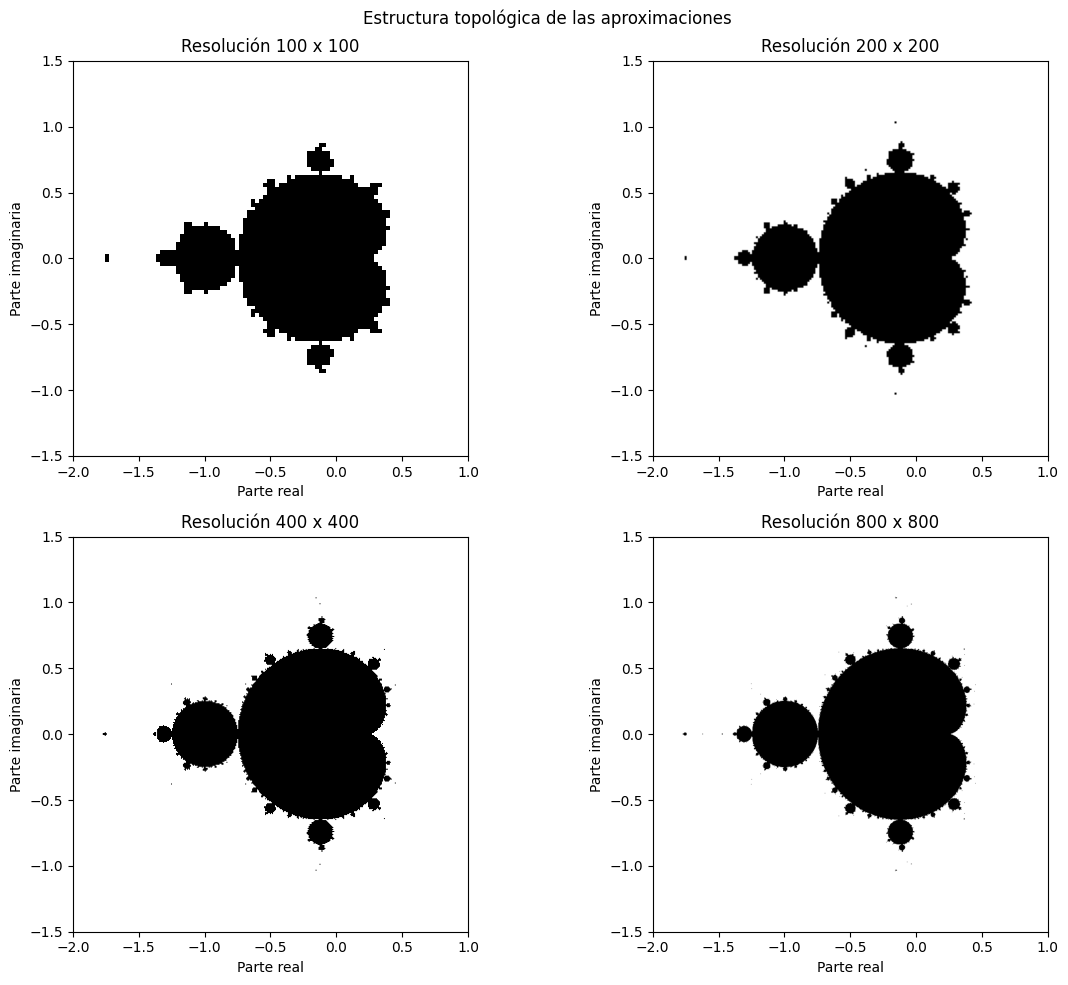

ANÁLISIS TOPOLÓGICO


,Resolución,Componentes conexas,Agujeros,Característica de Euler
0,100 x 100,2,0,2
1,200 x 200,6,2,4
2,400 x 400,17,4,13
3,800 x 800,54,32,22


In [ ]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.ndimage import (
    label,
    binary_fill_holes,
    generate_binary_structure
)

# Convenciones de conectividad:
# 8 vecinos para las componentes del conjunto.
# 4 vecinos para identificar los agujeros.
estructura_8 = generate_binary_structure(2, 2)
estructura_4 = generate_binary_structure(2, 1)

resultados_topologicos = []

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, r in enumerate(sorted(resultados.keys())):

    M = resultados[r]["no_escapados"].astype(bool)

    # Componentes conexas
    _, numero_componentes = label(
        M,
        structure=estructura_8
    )

    # Rellenar agujeros interiores
    relleno = binary_fill_holes(
        M,
        structure=estructura_4
    )

    agujeros = relleno & (~M)

    _, numero_agujeros = label(
        agujeros,
        structure=estructura_4
    )

    # Característica de Euler digital
    euler = numero_componentes - numero_agujeros

    resultados_topologicos.append({
        "Resolución": f"{r} x {r}",
        "Componentes conexas": numero_componentes,
        "Agujeros": numero_agujeros,
        "Característica de Euler": euler
    })

    axes[i].imshow(
        M,
        cmap="binary",
        origin="lower",
        extent=[-2, 1, -1.5, 1.5]
    )

    axes[i].set_title(f"Resolución {r} x {r}")
    axes[i].set_xlabel("Parte real")
    axes[i].set_ylabel("Parte imaginaria")

plt.suptitle("Estructura topológica de las aproximaciones")
plt.tight_layout()
plt.show()

tabla_topologica = pd.DataFrame(resultados_topologicos)

print("ANÁLISIS TOPOLÓGICO")
display(tabla_topologica)


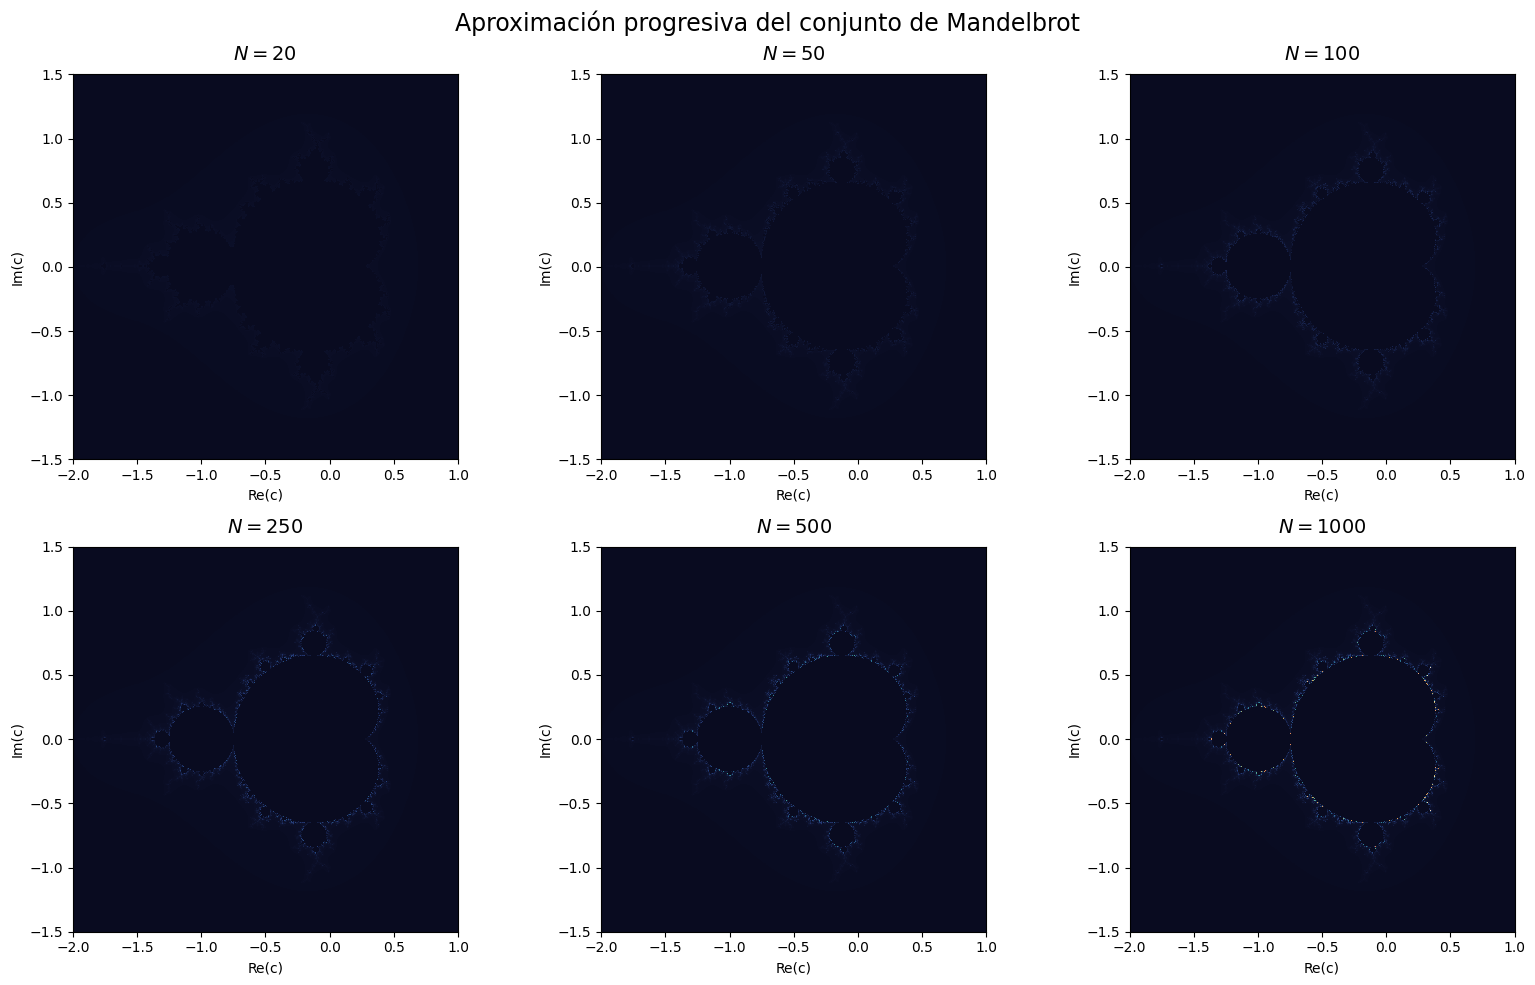

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

# =====================================================
# EXPERIMENTO: TRANSFORMACIÓN PROGRESIVA DE MANDELBROT
# =====================================================

# Dominio complejo
xmin, xmax = -2, 1
ymin, ymax = -1.5, 1.5

# Resolución fija
r = 800

# Valores de iteración
valores_N = [20, 50, 100, 250, 500, 1000]

# Malla compleja
x = np.linspace(xmin, xmax, r)
y = np.linspace(ymin, ymax, r)
X, Y = np.meshgrid(x, y)
C = X + 1j * Y

# Iteración
Z = np.zeros_like(C)
tiempo_escape = np.zeros(C.shape, dtype=np.int32)
activos = np.ones(C.shape, dtype=bool)

Nmax = max(valores_N)

for n in range(1, Nmax + 1):

    Z[activos] = Z[activos]**2 + C[activos]

    escapados = activos & (np.abs(Z) > 2)

    tiempo_escape[escapados] = n
    activos[escapados] = False

# Paleta propia para el seminario
colores = [
    "#090B20",
    "#263B78",
    "#286D91",
    "#42A69B",
    "#D6B65D",
    "#E77B43",
    "#F0D8B5"
]

mapa = LinearSegmentedColormap.from_list(
    "fractal_propio", colores, N=256
)

# =====================================================
# REPRESENTACIONES PARA DIFERENTES VALORES DE N
# =====================================================

fig, axes = plt.subplots(
    2, 3, figsize=(16, 10)
)

for ax, N in zip(axes.ravel(), valores_N):

    # Los puntos que todavía no escapan se conservan
    imagen = np.where(
        (tiempo_escape == 0) | (tiempo_escape > N),
        0,
        tiempo_escape
    )

    ax.imshow(
        imagen,
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=mapa,
        vmin=0,
        vmax=Nmax,
        interpolation="nearest"
    )

    ax.set_title(
        rf"$N={N}$",
        fontsize=14,
        pad=10
    )

    ax.set_xlabel("Re(c)")
    ax.set_ylabel("Im(c)")
    ax.set_aspect("equal")

fig.suptitle(
    "Aproximación progresiva del conjunto de Mandelbrot",
    fontsize=17,
    y=0.98
)

plt.tight_layout()
plt.savefig(
    "transformacion_progresiva_mandelbrot.png",
    dpi=350,
    bbox_inches="tight"
)
plt.show()

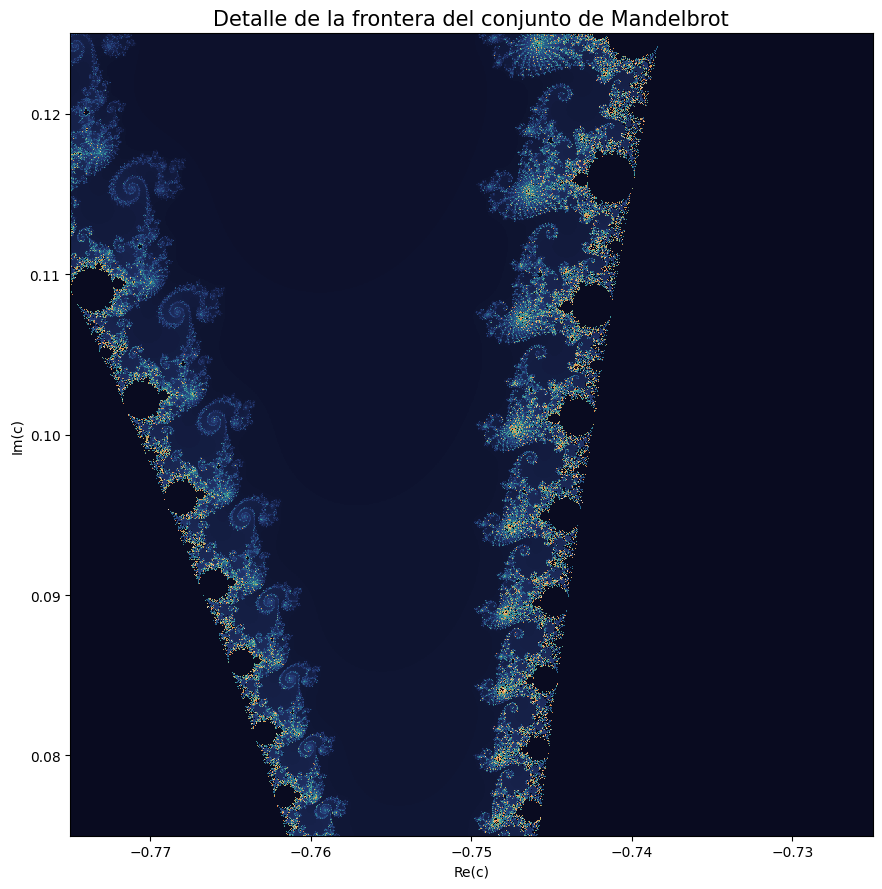

In [ ]:

# =====================================================
# ACERCAMIENTO A LA FRONTERA DE MANDELBROT
# =====================================================

# Región de interés
centro_x = -0.75
centro_y = 0.10

ancho = 0.025

zoom_r = 1200
zoom_N = 1000

zx = np.linspace(
    centro_x - ancho,
    centro_x + ancho,
    zoom_r
)

zy = np.linspace(
    centro_y - ancho,
    centro_y + ancho,
    zoom_r
)

ZX, ZY = np.meshgrid(zx, zy)
Czoom = ZX + 1j * ZY

Z = np.zeros_like(Czoom)
escape_zoom = np.zeros(
    Czoom.shape,
    dtype=np.int32
)

activos = np.ones(
    Czoom.shape,
    dtype=bool
)

for n in range(1, zoom_N + 1):

    Z[activos] = Z[activos]**2 + Czoom[activos]

    escapados = activos & (np.abs(Z) > 2)

    escape_zoom[escapados] = n
    activos[escapados] = False

# Visualización
fig, ax = plt.subplots(figsize=(10, 9))

ax.imshow(
    escape_zoom,
    extent=[
        centro_x - ancho,
        centro_x + ancho,
        centro_y - ancho,
        centro_y + ancho
    ],
    origin="lower",
    cmap=mapa,
    vmin=0,
    vmax=zoom_N,
    interpolation="nearest"
)

ax.set_title(
    "Detalle de la frontera del conjunto de Mandelbrot",
    fontsize=15
)

ax.set_xlabel("Re(c)")
ax.set_ylabel("Im(c)")
ax.set_aspect("equal")

plt.tight_layout()

plt.savefig(
    "detalle_frontera_mandelbrot.png",
    dpi=400,
    bbox_inches="tight"
)

plt.show()

Malla 100 x 100: 1660 puntos conservados
Malla 200 x 200: 6654 puntos conservados
Malla 400 x 400: 26779 puntos conservados
Malla 800 x 800: 107463 puntos conservados


,Resolución,Radio de cobertura epsilon,Puntos conservados
0,100,0.021427,1660
1,200,0.010660,6654
2,400,0.005317,26779
3,800,0.002655,107463


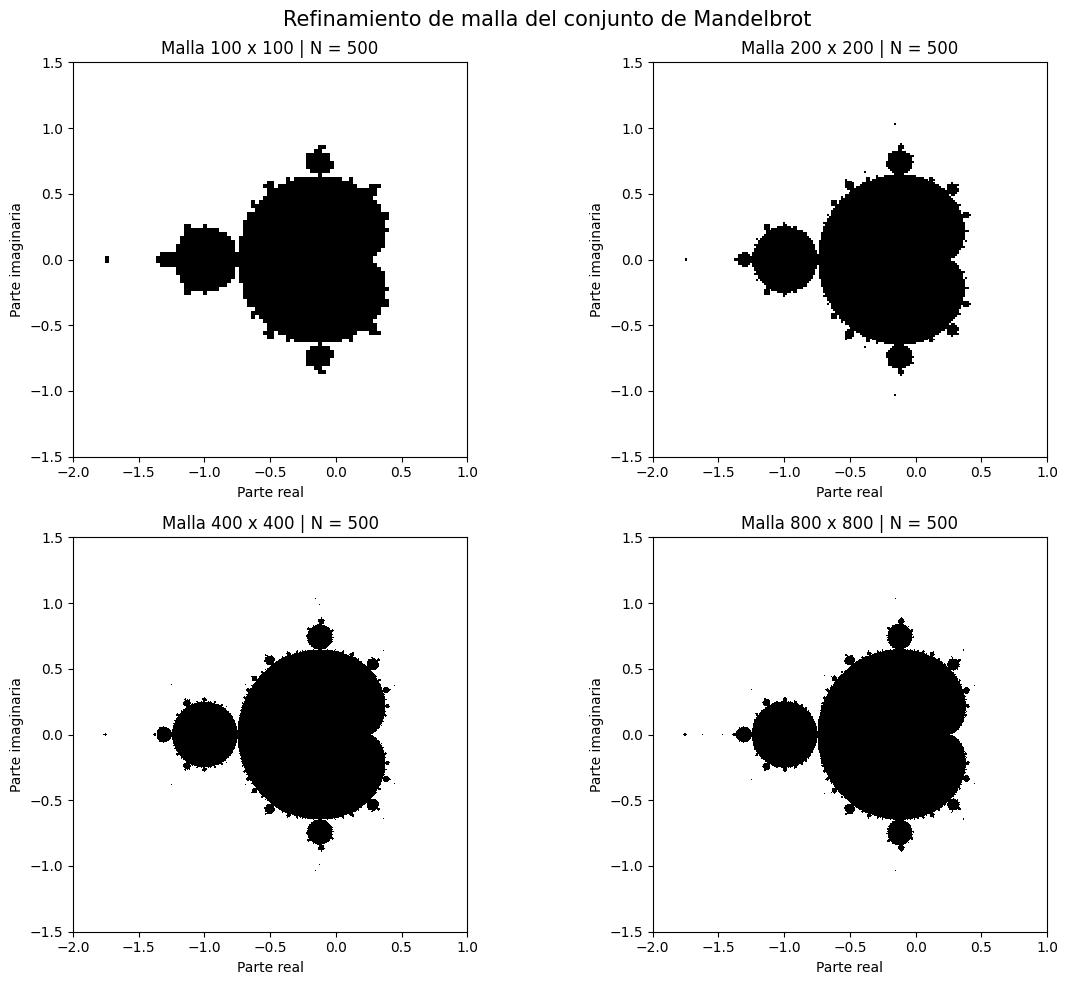

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import pandas as pd

# ==========================================
# 1. DOMINIO Y PARÁMETROS
# ==========================================

xmin, xmax = -2, 1
ymin, ymax = -1.5, 1.5

Nmax = 500

resoluciones = [100, 200, 400, 800]

# Negro: puntos conservados
# Blanco: puntos que escaparon
colores = ListedColormap(["white", "black"])


# ==========================================
# 2. FUNCIÓN DEL CONJUNTO DE MANDELBROT
# ==========================================

def mandelbrot(r, Nmax):

    x = np.linspace(xmin, xmax, r)
    y = np.linspace(ymin, ymax, r)

    X, Y = np.meshgrid(x, y)

    C = X + 1j * Y
    Z = np.zeros(C.shape, dtype=complex)

    activos = np.ones(C.shape, dtype=bool)

    for n in range(Nmax):

        Z[activos] = Z[activos]**2 + C[activos]

        escapan = activos & (np.abs(Z) > 2)

        activos[escapan] = False

        if not np.any(activos):
            break

    return activos


# ==========================================
# 3. CALCULAR LAS APROXIMACIONES
# ==========================================

resultados = {}
tabla = []

for r in resoluciones:

    M = mandelbrot(r, Nmax)

    resultados[r] = M

    hx = (xmax - xmin) / (r - 1)
    hy = (ymax - ymin) / (r - 1)

    epsilon = 0.5 * np.sqrt(hx**2 + hy**2)

    conservados = np.sum(M)

    tabla.append([
        r,
        epsilon,
        conservados
    ])

    print(f"Malla {r} x {r}: {conservados} puntos conservados")


# ==========================================
# 4. TABLA DE RESULTADOS
# ==========================================

df = pd.DataFrame(
    tabla,
    columns=[
        "Resolución",
        "Radio de cobertura epsilon",
        "Puntos conservados"
    ]
)

display(df)


# ==========================================
# 5. VISUALIZACIÓN DEL REFINAMIENTO
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(12, 10))

for ax, r in zip(axes.flat, resoluciones):

    ax.imshow(
        resultados[r],
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=colores,
        interpolation="nearest",
        vmin=0,
        vmax=1
    )

    ax.set_title(f"Malla {r} x {r} | N = {Nmax}")
    ax.set_xlabel("Parte real")
    ax.set_ylabel("Parte imaginaria")
    ax.set_aspect("equal")

plt.suptitle(
    "Refinamiento de malla del conjunto de Mandelbrot",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    "refinamiento_malla.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


,Resolución,Radio de cobertura epsilon,Puntos conservados
0,100,0.021427,1660
1,200,0.010660,6654
2,400,0.005317,26779
3,800,0.002655,107463


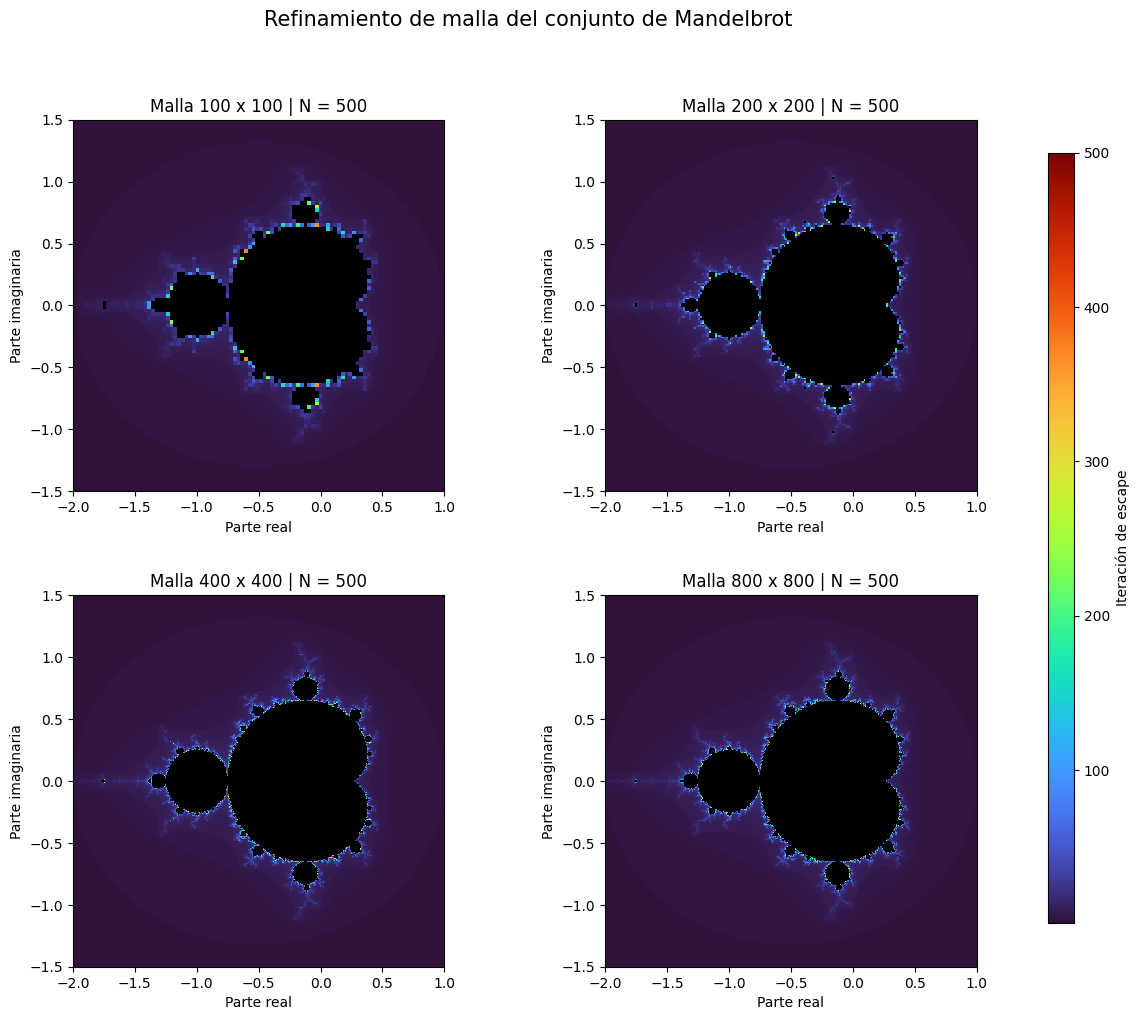

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import pandas as pd

# ==========================================
# 1. DOMINIO Y PARÁMETROS
# ==========================================

xmin, xmax = -2, 1
ymin, ymax = -1.5, 1.5

Nmax = 500
resoluciones = [100, 200, 400, 800]


# ==========================================
# 2. FUNCIÓN DE MANDELBROT
# ==========================================

def mandelbrot(r, Nmax):

    x = np.linspace(xmin, xmax, r)
    y = np.linspace(ymin, ymax, r)

    X, Y = np.meshgrid(x, y)
    C = X + 1j * Y

    Z = np.zeros(C.shape, dtype=complex)

    activos = np.ones(C.shape, dtype=bool)

    # Registrar iteración de escape
    escape = np.zeros(C.shape, dtype=int)

    for n in range(1, Nmax + 1):

        Z[activos] = Z[activos]**2 + C[activos]

        escapan = activos & (np.abs(Z) > 2)

        escape[escapan] = n

        activos[escapan] = False

        if not np.any(activos):
            break

    return escape, activos


# ==========================================
# 3. CALCULAR LAS MALLAS
# ==========================================

resultados = {}
tabla = []

for r in resoluciones:

    escape, conservados = mandelbrot(r, Nmax)

    resultados[r] = (escape, conservados)

    hx = (xmax - xmin) / (r - 1)
    hy = (ymax - ymin) / (r - 1)

    epsilon = 0.5 * np.sqrt(hx**2 + hy**2)

    tabla.append([
        r,
        epsilon,
        np.sum(conservados)
    ])

df = pd.DataFrame(
    tabla,
    columns=[
        "Resolución",
        "Radio de cobertura epsilon",
        "Puntos conservados"
    ]
)

display(df)


# ==========================================
# 4. VISUALIZACIÓN A COLOR
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(13, 11))

for ax, r in zip(axes.flat, resoluciones):

    escape, conservados = resultados[r]

    # Los puntos conservados reciben valor -1
    imagen = escape.astype(float)
    imagen[conservados] = -1

    # Mostrar exterior a color e interior negro
    cmap = plt.colormaps["turbo"].copy()
    cmap.set_under("black")

    im = ax.imshow(
        imagen,
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=cmap,
        vmin=1,
        vmax=Nmax,
        interpolation="nearest",
        aspect="equal"
    )

    ax.set_title(f"Malla {r} x {r} | N = {Nmax}")
    ax.set_xlabel("Parte real")
    ax.set_ylabel("Parte imaginaria")

fig.suptitle(
    "Refinamiento de malla del conjunto de Mandelbrot",
    fontsize=15
)

fig.subplots_adjust(
    right=0.87,
    hspace=0.28,
    wspace=0.22
)

cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])

cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("Iteración de escape")

plt.savefig(
    "refinamiento_malla.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


N = 10: 143658 puntos conservados
N = 50: 112656 puntos conservados
N = 100: 109662 puntos conservados
N = 500: 107463 puntos conservados


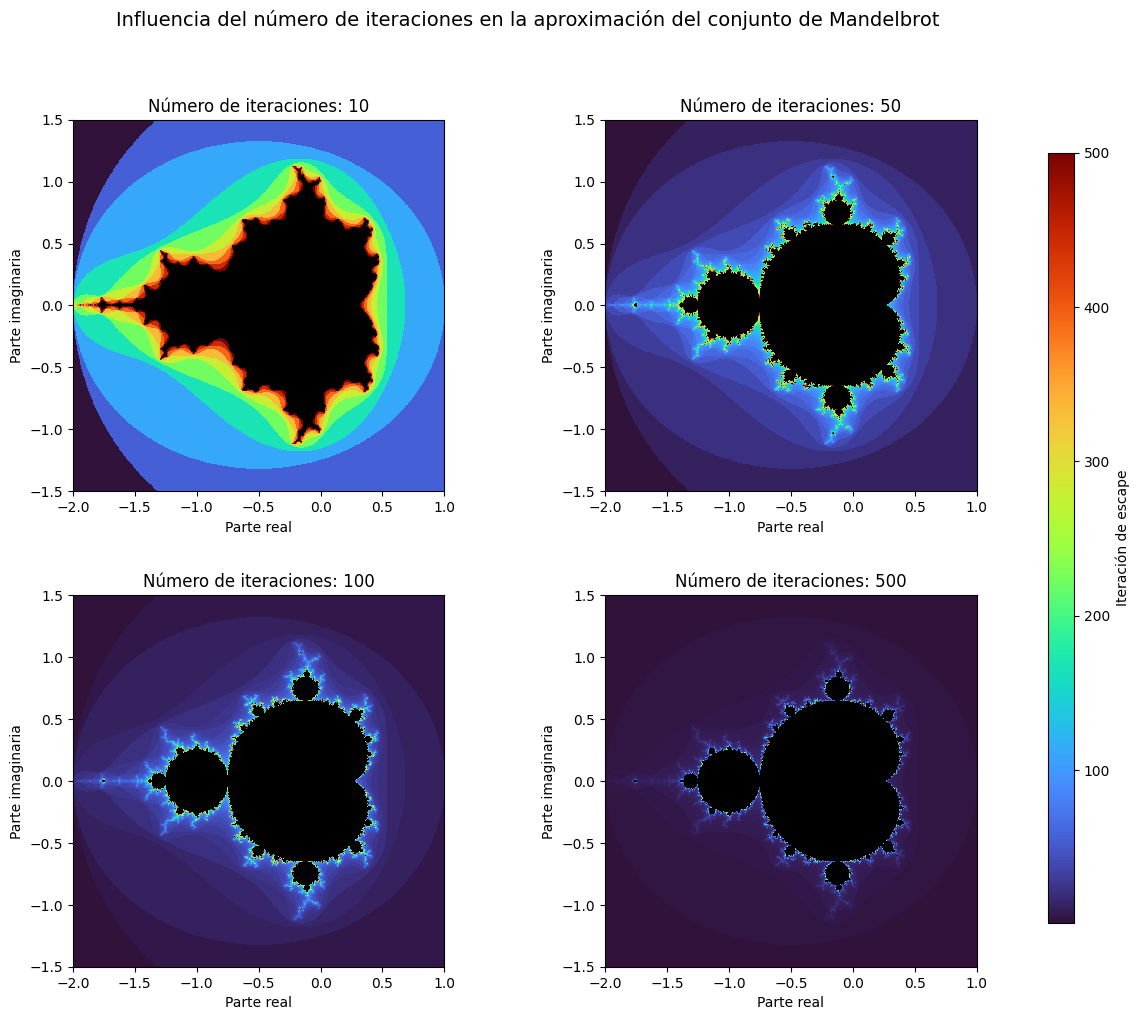

In [ ]:

import numpy as np
import matplotlib.pyplot as plt

# ==========================================
# 1. PARÁMETROS FIJOS
# ==========================================

xmin, xmax = -2, 1
ymin, ymax = -1.5, 1.5

R = 800

iteraciones = [10, 50, 100, 500]

# ==========================================
# 2. CONSTRUIR LA MALLA
# ==========================================

x = np.linspace(xmin, xmax, R)
y = np.linspace(ymin, ymax, R)

X, Y = np.meshgrid(x, y)

C = X + 1j * Y

# ==========================================
# 3. FUNCIÓN DE MANDELBROT
# ==========================================

def mandelbrot_iteraciones(C, Nmax):

    Z = np.zeros(C.shape, dtype=complex)

    activos = np.ones(C.shape, dtype=bool)

    escape = np.zeros(C.shape, dtype=int)

    for n in range(1, Nmax + 1):

        Z[activos] = Z[activos]**2 + C[activos]

        escapan = activos & (np.abs(Z) > 2)

        escape[escapan] = n

        activos[escapan] = False

        if not np.any(activos):
            break

    return escape, activos

# ==========================================
# 4. CALCULAR LAS APROXIMACIONES
# ==========================================

resultados = {}

for N in iteraciones:

    escape, conservados = mandelbrot_iteraciones(C, N)

    resultados[N] = (escape, conservados)

    print(
        f"N = {N}: "
        f"{np.sum(conservados)} puntos conservados"
    )

# ==========================================
# 5. VISUALIZACIÓN A COLOR
# ==========================================

fig, axes = plt.subplots(2, 2, figsize=(13, 11))

for ax, N in zip(axes.flat, iteraciones):

    escape, conservados = resultados[N]

    imagen = escape.astype(float)

    # Los puntos que no escaparon permanecen negros
    imagen[conservados] = -1

    cmap = plt.colormaps["turbo"].copy()
    cmap.set_under("black")

    im = ax.imshow(
        imagen,
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap=cmap,
        vmin=1,
        vmax=N,
        interpolation="nearest",
        aspect="equal"
    )

    ax.set_title(f"Número de iteraciones: {N}")
    ax.set_xlabel("Parte real")
    ax.set_ylabel("Parte imaginaria")

# ==========================================
# 6. BARRA DE COLORES Y PRESENTACIÓN
# ==========================================

fig.suptitle(
    "Influencia del número de iteraciones "
    "en la aproximación del conjunto de Mandelbrot",
    fontsize=14
)

fig.subplots_adjust(
    right=0.87,
    hspace=0.28,
    wspace=0.22
)

cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7])

cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label("Iteración de escape")

plt.savefig(
    "aproximacion_iteraciones.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

/tmp/ipykernel_7495/1735245065.py:94: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


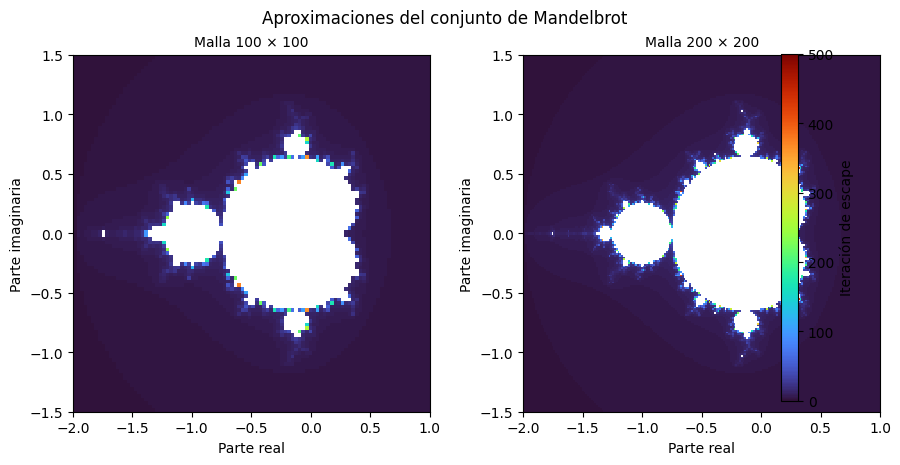

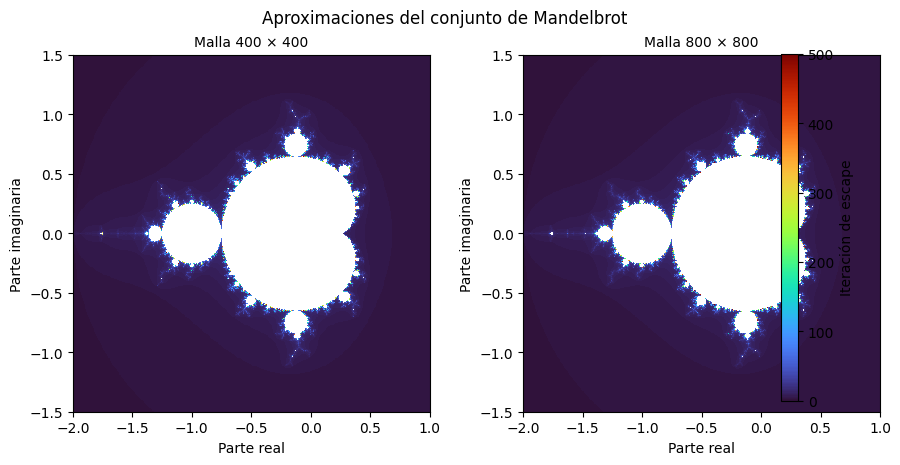

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# -----------------------------------------
# PARÁMETROS DEL CONJUNTO DE MANDELBROT
# -----------------------------------------

NMAX = 500

x_min, x_max = -2, 1
y_min, y_max = -1.5, 1.5

resoluciones = [100, 200, 400, 800]

# -----------------------------------------
# FUNCIÓN DE ITERACIÓN
# -----------------------------------------

def calcular_mandelbrot(resolucion):

    x = np.linspace(x_min, x_max, resolucion)
    y = np.linspace(y_min, y_max, resolucion)

    C = x[np.newaxis, :] + 1j * y[:, np.newaxis]
    Z = np.zeros_like(C)

    escape = np.zeros(C.shape, dtype=float)
    activos = np.ones(C.shape, dtype=bool)

    for n in range(NMAX):

        Z[activos] = Z[activos]**2 + C[activos]

        escapados = activos & (np.abs(Z) > 2)

        escape[escapados] = n + 1
        activos[escapados] = False

        if not np.any(activos):
            break

    escape[activos] = NMAX

    return escape


# -----------------------------------------
# FUNCIÓN PARA GENERAR CADA IMAGEN
# -----------------------------------------

def generar_imagen(resoluciones_grupo, nombre_archivo, titulo):

    fig, axes = plt.subplots(1, 2, figsize=(9, 4.5))

    imagen = None

    for ax, r in zip(axes, resoluciones_grupo):

        datos = calcular_mandelbrot(r)

        # Los puntos que no escapan se muestran en negro
        datos = np.ma.masked_where(datos == NMAX, datos)

        imagen = ax.imshow(
            datos,
            extent=[x_min, x_max, y_min, y_max],
            origin="lower",
            cmap="turbo",
            norm=Normalize(vmin=0, vmax=NMAX),
            interpolation="nearest",
            aspect="equal"
        )

        ax.set_title(f"Malla {r} × {r}", fontsize=10)
        ax.set_xlabel("Parte real")
        ax.set_ylabel("Parte imaginaria")

        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)

    # Barra de color compartida
    fig.colorbar(
        imagen,
        ax=axes,
        orientation="vertical",
        fraction=0.035,
        pad=0.04,
        label="Iteración de escape"
    )

    fig.suptitle(titulo, fontsize=12)

    plt.tight_layout()

    plt.savefig(
        nombre_archivo,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# -----------------------------------------
# PRIMERA IMAGEN: DOS PRIMERAS RESOLUCIONES
# -----------------------------------------

generar_imagen(
    [100, 200],
    "refinamiento_superior.png",
    "Aproximaciones del conjunto de Mandelbrot"
)


# -----------------------------------------
# SEGUNDA IMAGEN: DOS ÚLTIMAS RESOLUCIONES
# -----------------------------------------

generar_imagen(
    [400, 800],
    "refinamiento_inferior.png",
    "Aproximaciones del conjunto de Mandelbrot"
)


# -----------------------------------------
# DESCARGAR LAS DOS IMÁGENES
# -----------------------------------------

from google.colab import files

files.download("refinamiento_superior.png")
files.download("refinamiento_inferior.png")


Calculando malla 100 x 100...
Calculando malla 200 x 200...
Calculando malla 400 x 400...
Calculando malla 800 x 800...
Cálculos terminados.


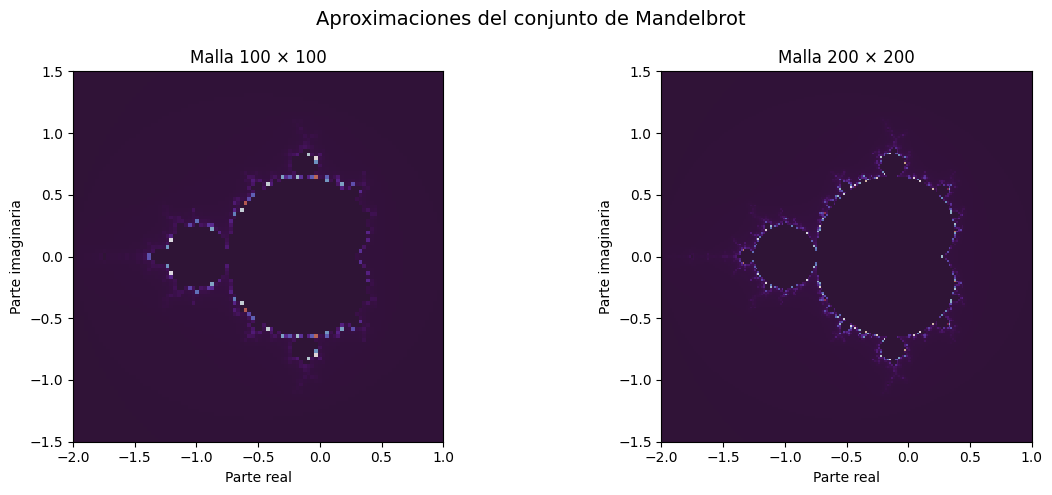

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

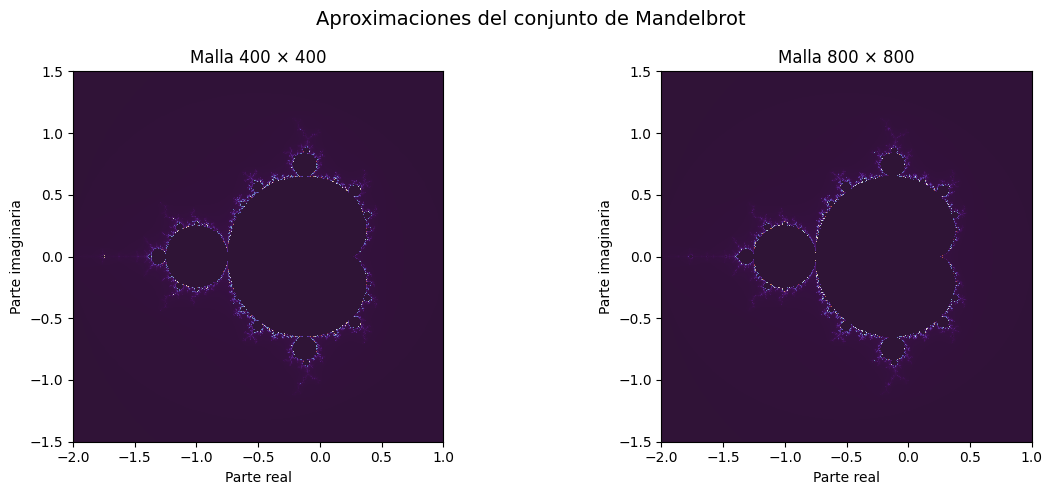

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

# Parámetros del conjunto de Mandelbrot
N = 500
xmin, xmax = -2, 1
ymin, ymax = -1.5, 1.5

# Función para calcular la aproximación del conjunto
def mandelbrot(resolucion):
    x = np.linspace(xmin, xmax, resolucion)
    y = np.linspace(ymin, ymax, resolucion)

    X, Y = np.meshgrid(x, y)
    C = X + 1j * Y

    Z = np.zeros_like(C)
    escape = np.zeros(C.shape, dtype=int)

    activos = np.ones(C.shape, dtype=bool)

    for n in range(N):
        Z[activos] = Z[activos]**2 + C[activos]

        escapados = activos & (np.abs(Z) > 2)
        escape[escapados] = n + 1

        activos[escapados] = False

        if not np.any(activos):
            break

    escape[activos] = N

    return escape


# Generar las cuatro resoluciones
resoluciones = [100, 200, 400, 800]

resultados = {}

for r in resoluciones:
    print(f"Calculando malla {r} x {r}...")
    resultados[r] = mandelbrot(r)

print("Cálculos terminados.")


# ------------------------------------------------
# PRIMERA IMAGEN: MALLAS 100 x 100 Y 200 x 200
# ------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, r in zip(axes, [100, 200]):
    ax.imshow(
        resultados[r],
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap="twilight_shifted",
        vmin=0,
        vmax=N,
        interpolation="nearest",
        aspect="equal"
    )

    ax.set_title(f"Malla {r} × {r}")
    ax.set_xlabel("Parte real")
    ax.set_ylabel("Parte imaginaria")

fig.suptitle(
    "Aproximaciones del conjunto de Mandelbrot",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    "refinamiento_superior.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Descargar primera imagen
files.download("refinamiento_superior.png")


# ------------------------------------------------
# SEGUNDA IMAGEN: MALLAS 400 x 400 Y 800 x 800
# ------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, r in zip(axes, [400, 800]):
    ax.imshow(
        resultados[r],
        extent=[xmin, xmax, ymin, ymax],
        origin="lower",
        cmap="twilight_shifted",
        vmin=0,
        vmax=N,
        interpolation="nearest",
        aspect="equal"
    )

    ax.set_title(f"Malla {r} × {r}")
    ax.set_xlabel("Parte real")
    ax.set_ylabel("Parte imaginaria")

fig.suptitle(
    "Aproximaciones del conjunto de Mandelbrot",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    "refinamiento_inferior.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Descargar segunda imagen
files.download("refinamiento_inferior.png")

Calculando resolución 100 x 100...
Calculando resolución 200 x 200...
Calculando resolución 400 x 400...
Calculando resolución 800 x 800...
Cálculos terminados.


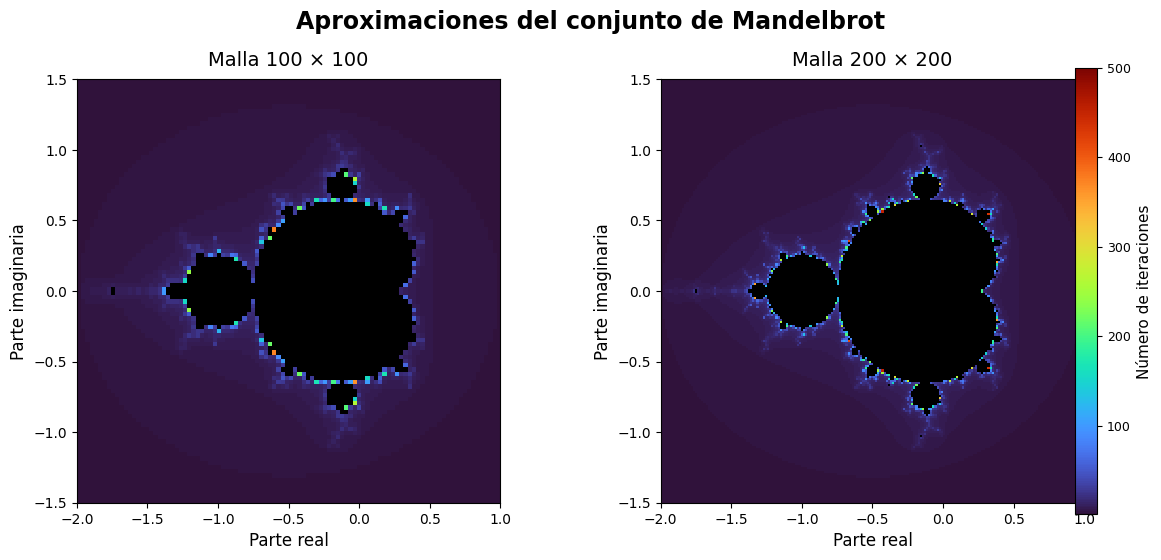

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

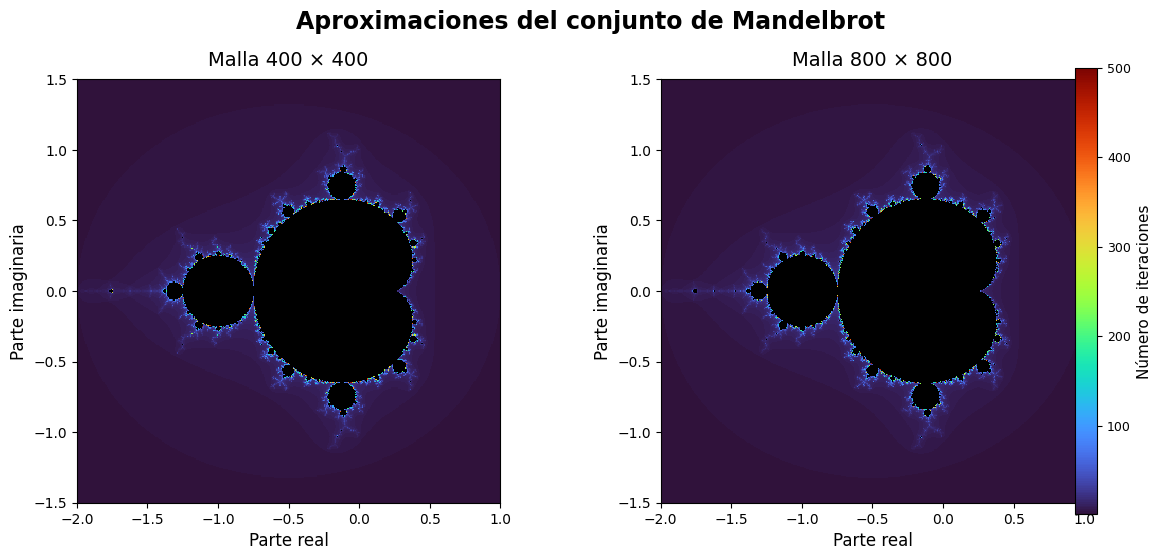

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from google.colab import files

# ==========================================
# PARÁMETROS
# ==========================================

N = 500

xmin, xmax = -2, 1
ymin, ymax = -1.5, 1.5

# ==========================================
# FUNCIÓN DE MANDELBROT
# ==========================================

def mandelbrot(resolucion):

    x = np.linspace(xmin, xmax, resolucion)
    y = np.linspace(ymin, ymax, resolucion)

    X, Y = np.meshgrid(x, y)
    C = X + 1j * Y

    Z = np.zeros_like(C)

    iteraciones = np.zeros(C.shape, dtype=float)
    activos = np.ones(C.shape, dtype=bool)

    for n in range(N):

        Z[activos] = Z[activos]**2 + C[activos]

        escapados = activos & (np.abs(Z) > 2)

        iteraciones[escapados] = n + 1
        activos[escapados] = False

        if not np.any(activos):
            break

    # Los puntos que no escapan pertenecen
    # a la aproximación del conjunto.

    return iteraciones, activos


# ==========================================
# CALCULAR LAS CUATRO RESOLUCIONES
# ==========================================

resoluciones = [100, 200, 400, 800]

resultados = {}

for r in resoluciones:
    print(f"Calculando resolución {r} x {r}...")
    resultados[r] = mandelbrot(r)

print("Cálculos terminados.")


# ==========================================
# CONFIGURACIÓN DE LAS GRÁFICAS
# ==========================================

cmap = plt.cm.turbo.copy()
cmap.set_bad(color="black")

norm = Normalize(vmin=1, vmax=N)


def generar_imagen(resoluciones, nombre_archivo):

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 5.8)
    )

    fig.suptitle(
        "Aproximaciones del conjunto de Mandelbrot",
        fontsize=17,
        fontweight="bold",
        y=0.98
    )

    for ax, r in zip(axes, resoluciones):

        iteraciones, activos = resultados[r]

        datos = np.ma.masked_where(
            activos,
            iteraciones
        )

        imagen = ax.imshow(
            datos,
            extent=[xmin, xmax, ymin, ymax],
            origin="lower",
            cmap=cmap,
            norm=norm,
            interpolation="nearest",
            aspect="equal"
        )

        ax.set_title(
            f"Malla {r} × {r}",
            fontsize=14,
            pad=10
        )

        ax.set_xlabel(
            "Parte real",
            fontsize=12
        )

        ax.set_ylabel(
            "Parte imaginaria",
            fontsize=12
        )

        ax.set_xlim(xmin, xmax)
        ax.set_ylim(ymin, ymax)

        ax.tick_params(labelsize=10)

    # Barra de colores compartida
    cbar = fig.colorbar(
        imagen,
        ax=axes,
        orientation="vertical",
        fraction=0.035,
        pad=0.04
    )

    cbar.set_label(
        "Número de iteraciones",
        fontsize=11
    )

    cbar.ax.tick_params(labelsize=9)

    fig.subplots_adjust(
        left=0.08,
        right=0.88,
        bottom=0.13,
        top=0.86,
        wspace=0.28
    )

    plt.savefig(
        nombre_archivo,
        dpi=400,
        bbox_inches="tight",
        facecolor="white"
    )

    plt.show()

    plt.close(fig)

    files.download(nombre_archivo)


# ==========================================
# PRIMERA IMAGEN
# ==========================================

generar_imagen(
    [100, 200],
    "refinamiento_superior.png"
)


# ==========================================
# SEGUNDA IMAGEN
# ==========================================

generar_imagen(
    [400, 800],
    "refinamiento_inferior.png"
)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Calculando malla 100 x 100...
Calculando malla 200 x 200...
Cálculos terminados.


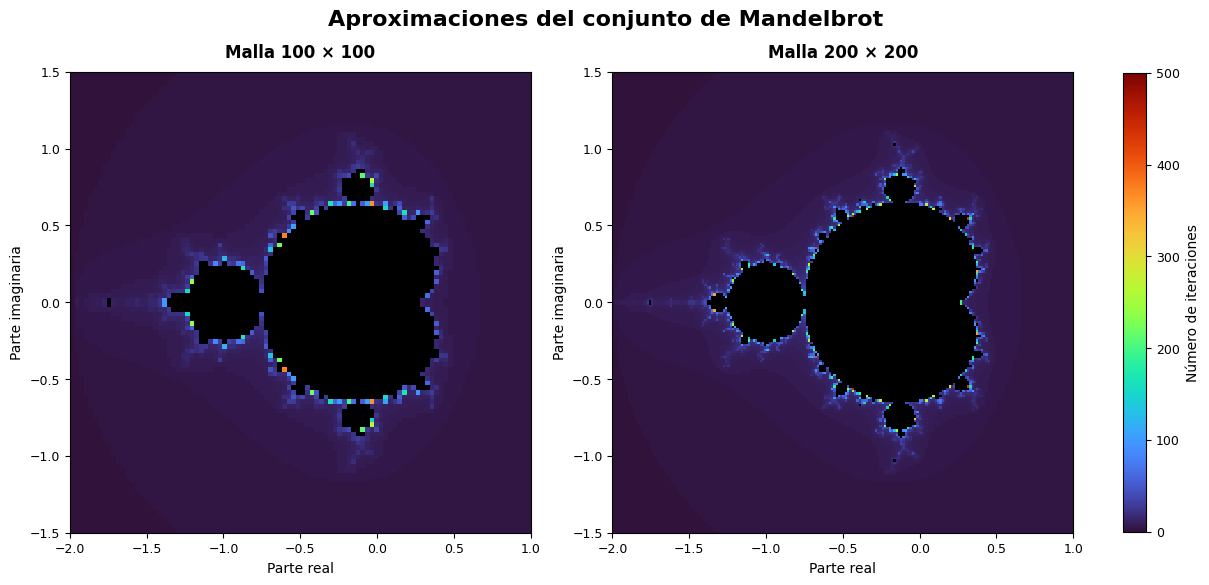

Imagen guardada como: refinamiento_superior.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

# --------------------------------------------------
# PARÁMETROS DEL CONJUNTO DE MANDELBROT
# --------------------------------------------------

N = 500

# Dominio del plano complejo
x_min, x_max = -2, 1
y_min, y_max = -1.5, 1.5

# Resoluciones que aparecerán en la primera imagen
resoluciones = [100, 200]


# --------------------------------------------------
# FUNCIÓN PARA CALCULAR EL CONJUNTO DE MANDELBROT
# --------------------------------------------------

def calcular_mandelbrot(resolucion, max_iter):

    x = np.linspace(x_min, x_max, resolucion)
    y = np.linspace(y_min, y_max, resolucion)

    C = x[np.newaxis, :] + 1j * y[:, np.newaxis]

    Z = np.zeros_like(C)
    iteraciones = np.zeros(C.shape, dtype=int)

    activos = np.ones(C.shape, dtype=bool)

    for n in range(max_iter):

        Z[activos] = Z[activos]**2 + C[activos]

        escaparon = (np.abs(Z) > 2) & activos

        iteraciones[escaparon] = n + 1

        activos[escaparon] = False

        if not np.any(activos):
            break

    # Los puntos que no escaparon permanecen en negro
    resultado = iteraciones.astype(float)
    resultado[activos] = -1

    return resultado


# --------------------------------------------------
# CÁLCULO DE LAS DOS APROXIMACIONES
# --------------------------------------------------

resultados = []

for r in resoluciones:

    print(f"Calculando malla {r} x {r}...")

    datos = calcular_mandelbrot(r, N)

    resultados.append(datos)

print("Cálculos terminados.")


# --------------------------------------------------
# GENERACIÓN DE LA PRIMERA FIGURA
# --------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5.8),
    constrained_layout=True
)

fig.suptitle(
    "Aproximaciones del conjunto de Mandelbrot",
    fontsize=16,
    fontweight="bold"
)

# Mapa de colores
cmap = plt.cm.turbo.copy()
cmap.set_under("black")

norm = Normalize(vmin=0, vmax=N)

for ax, datos, r in zip(axes, resultados, resoluciones):

    imagen = ax.imshow(
        datos,
        extent=[x_min, x_max, y_min, y_max],
        origin="lower",
        cmap=cmap,
        norm=norm,
        interpolation="nearest",
        aspect="equal"
    )

    ax.set_title(
        f"Malla {r} × {r}",
        fontsize=12,
        fontweight="bold",
        pad=10
    )

    ax.set_xlabel("Parte real", fontsize=10)
    ax.set_ylabel("Parte imaginaria", fontsize=10)

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ax.tick_params(labelsize=9)

# Barra de colores independiente, al extremo derecho
barra = fig.colorbar(
    imagen,
    ax=axes,
    location="right",
    fraction=0.045,
    pad=0.04,
    shrink=0.88
)

barra.set_label(
    "Número de iteraciones",
    fontsize=10
)

barra.ax.tick_params(labelsize=9)

# Guardar imagen en alta resolución
nombre = "refinamiento_superior.png"

fig.savefig(
    nombre,
    dpi=400,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

print(f"Imagen guardada como: {nombre}")


# --------------------------------------------------
# DESCARGAR LA IMAGEN
# --------------------------------------------------

from google.colab import files

files.download(nombre)

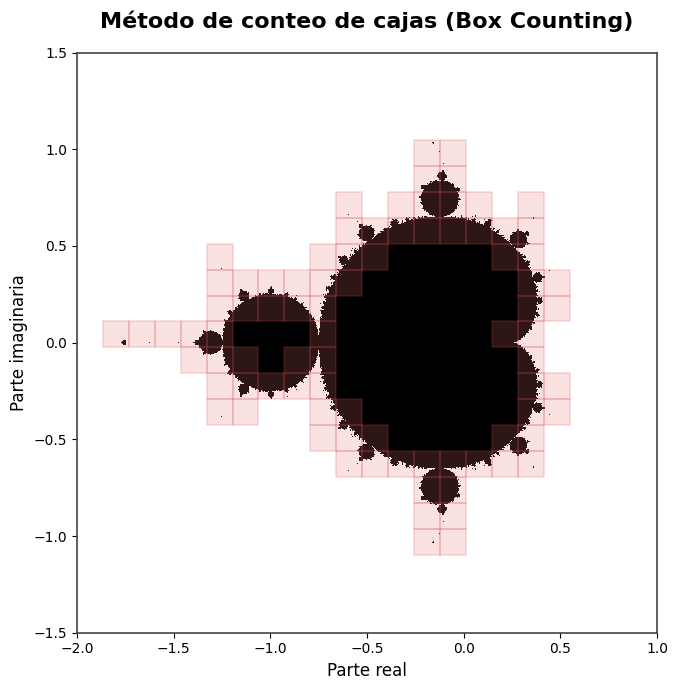

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

# --------------------------------------------------
# 1. Construcción del conjunto de Mandelbrot
# --------------------------------------------------

resolucion = 850
N = 180

x = np.linspace(-2.0, 1.0, resolucion)
y = np.linspace(-1.5, 1.5, resolucion)

X, Y = np.meshgrid(x, y)
C = X + 1j * Y
Z = np.zeros_like(C)

conjunto = np.ones(C.shape, dtype=bool)

for k in range(N):
    Z[conjunto] = Z[conjunto]**2 + C[conjunto]
    conjunto[np.abs(Z) > 2] = False

# --------------------------------------------------
# 2. Identificación de la frontera
# --------------------------------------------------

frontera = np.zeros_like(conjunto, dtype=bool)

frontera[1:, :] |= conjunto[1:, :] != conjunto[:-1, :]
frontera[:-1, :] |= conjunto[:-1, :] != conjunto[1:, :]
frontera[:, 1:] |= conjunto[:, 1:] != conjunto[:, :-1]
frontera[:, :-1] |= conjunto[:, :-1] != conjunto[:, 1:]

# --------------------------------------------------
# 3. Configuración del conteo de cajas
# --------------------------------------------------

tamano_caja = 38

fig, ax = plt.subplots(figsize=(10, 7))

# Fondo y conjunto
ax.set_facecolor("#F7F8FA")

ax.imshow(
    conjunto,
    extent=[-2, 1, -1.5, 1.5],
    origin="lower",
    cmap="Greys",
    interpolation="nearest"
)

# --------------------------------------------------
# 4. Dibujar las cajas que intersectan la frontera
# --------------------------------------------------

for i in range(0, resolucion, tamano_caja):
    for j in range(0, resolucion, tamano_caja):

        bloque = frontera[
            i:min(i + tamano_caja, resolucion),
            j:min(j + tamano_caja, resolucion)
        ]

        if np.any(bloque):

            x0 = -2 + 3 * j / resolucion
            y0 = -1.5 + 3 * i / resolucion

            ancho = 3 * min(tamano_caja, resolucion-j) / resolucion
            alto = 3 * min(tamano_caja, resolucion-i) / resolucion

            caja = Rectangle(
                (x0, y0),
                ancho,
                alto,
                linewidth=1.15,
                edgecolor="#D94848",
                facecolor="#E76F6F",
                alpha=0.20
            )

            ax.add_patch(caja)

# --------------------------------------------------
# 5. Presentación de la figura
# --------------------------------------------------

ax.set_title(
    "Método de conteo de cajas (Box Counting)",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel("Parte real", fontsize=12)
ax.set_ylabel("Parte imaginaria", fontsize=12)

ax.set_xlim(-2, 1)
ax.set_ylim(-1.5, 1.5)

ax.set_aspect("equal")
ax.grid(False)

for spine in ax.spines.values():
    spine.set_color("#444444")
    spine.set_linewidth(1.2)

plt.tight_layout()

# --------------------------------------------------
# 6. Guardar imagen
# --------------------------------------------------

nombre = "box_counting_mandelbrot.png"

plt.savefig(
    nombre,
    dpi=350,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

from google.colab import files
files.download(nombre)

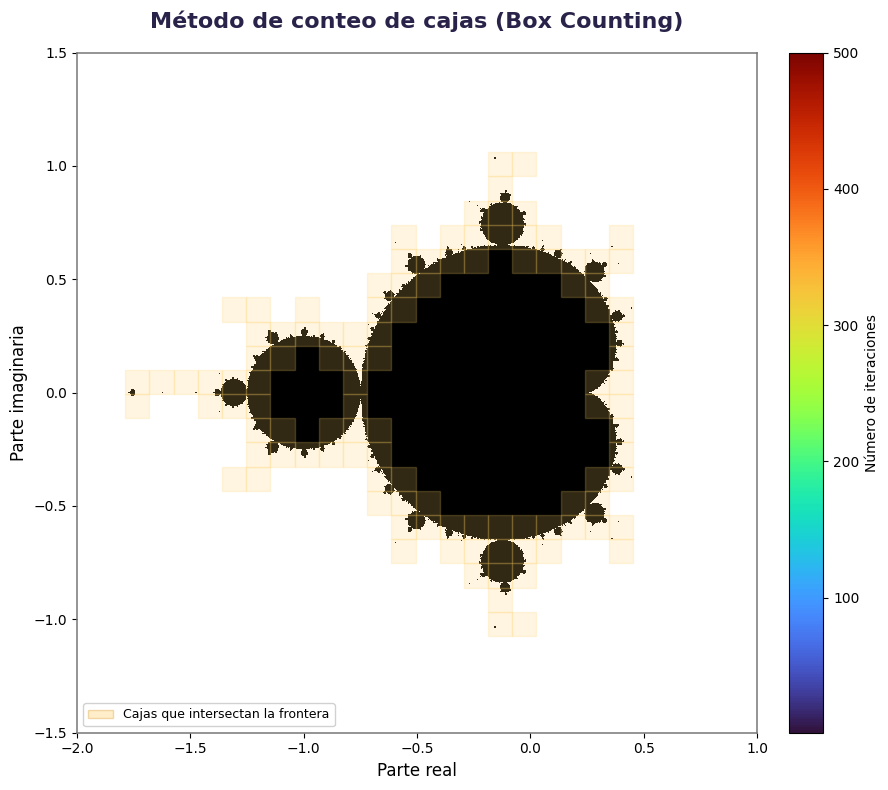

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch

# ==================================================
# 1. PARÁMETROS DE LA APROXIMACIÓN
# ==================================================

resolucion = 900
N = 500
tamano_caja = 32

xmin, xmax = -2.0, 1.0
ymin, ymax = -1.5, 1.5

x = np.linspace(xmin, xmax, resolucion)
y = np.linspace(ymin, ymax, resolucion)

X, Y = np.meshgrid(x, y)
C = X + 1j * Y

Z = np.zeros_like(C, dtype=complex)
activos = np.ones(C.shape, dtype=bool)

# Registro del número de iteraciones hasta el escape
iteraciones = np.zeros(C.shape, dtype=int)

# ==================================================
# 2. CONSTRUCCIÓN DEL CONJUNTO DE MANDELBROT
# ==================================================

for k in range(1, N + 1):

    Z[activos] = Z[activos]**2 + C[activos]

    escapan = activos & (np.abs(Z) > 2)

    iteraciones[escapan] = k
    activos[escapan] = False

conjunto = activos.copy()

# ==================================================
# 3. IDENTIFICACIÓN DE LA FRONTERA
# ==================================================

frontera = np.zeros_like(conjunto, dtype=bool)

frontera[1:, :] |= conjunto[1:, :] != conjunto[:-1, :]
frontera[:-1, :] |= conjunto[:-1, :] != conjunto[1:, :]

frontera[:, 1:] |= conjunto[:, 1:] != conjunto[:, :-1]
frontera[:, :-1] |= conjunto[:, :-1] != conjunto[:, 1:]

# ==================================================
# 4. REPRESENTACIÓN DEL CONJUNTO
# ==================================================

fig, ax = plt.subplots(figsize=(10, 8))

ax.set_facecolor("#17152F")

# Representación de los puntos que escapan
datos = np.ma.masked_where(conjunto, iteraciones)

imagen = ax.imshow(
    datos,
    extent=[xmin, xmax, ymin, ymax],
    origin="lower",
    cmap="turbo",
    interpolation="bilinear",
    vmin=1,
    vmax=N
)

# El conjunto se representa en negro
ax.imshow(
    conjunto,
    extent=[xmin, xmax, ymin, ymax],
    origin="lower",
    cmap="gray_r",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

# ==================================================
# 5. CONTEO DE CAJAS SOBRE LA FRONTERA
# ==================================================

for i in range(0, resolucion, tamano_caja):
    for j in range(0, resolucion, tamano_caja):

        bloque = frontera[
            i:min(i + tamano_caja, resolucion),
            j:min(j + tamano_caja, resolucion)
        ]

        if np.any(bloque):

            x0 = xmin + (xmax - xmin) * j / resolucion
            y0 = ymin + (ymax - ymin) * i / resolucion

            ancho = (xmax - xmin) * min(
                tamano_caja, resolucion - j
            ) / resolucion

            alto = (ymax - ymin) * min(
                tamano_caja, resolucion - i
            ) / resolucion

            caja = Rectangle(
                (x0, y0),
                ancho,
                alto,
                linewidth=1.0,
                edgecolor="#FFD166",
                facecolor="#FFD166",
                alpha=0.20
            )

            ax.add_patch(caja)

# ==================================================
# 6. FORMATO Y PRESENTACIÓN
# ==================================================

ax.set_title(
    "Método de conteo de cajas (Box Counting)",
    fontsize=16,
    fontweight="bold",
    color="#29234A",
    pad=18
)

ax.set_xlabel("Parte real", fontsize=12)
ax.set_ylabel("Parte imaginaria", fontsize=12)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")

ax.grid(False)

for borde in ax.spines.values():
    borde.set_color("#777777")
    borde.set_linewidth(1.1)

# Barra de color
barra = plt.colorbar(imagen, ax=ax, fraction=0.045, pad=0.035)
barra.set_label(
    "Número de iteraciones",
    fontsize=10
)

# Leyenda de las cajas
leyenda = Patch(
    facecolor="#FFD166",
    edgecolor="#D99A28",
    alpha=0.35,
    label="Cajas que intersectan la frontera"
)

ax.legend(
    handles=[leyenda],
    loc="lower left",
    fontsize=9,
    framealpha=0.9
)

plt.tight_layout()

# ==================================================
# 7. GUARDAR LA IMAGEN
# ==================================================

nombre = "box_counting_mandelbrot.png"

plt.savefig(
    nombre,
    dpi=350,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Descargar imagen
from google.colab import files
files.download(nombre)

In [ ]:
# ==================================================
# 5. CONTEO DE CAJAS SOBRE LA FRONTERA
# ==================================================

for i in range(0, resolucion, tamano_caja):
    for j in range(0, resolucion, tamano_caja):

        bloque = frontera[
            i:min(i + tamano_caja, resolucion),
            j:min(j + tamano_caja, resolucion)
        ]

        if np.any(bloque):

            x0 = xmin + (xmax - xmin) * j / resolucion
            y0 = ymin + (ymax - ymin) * i / resolucion

            ancho = (xmax - xmin) * min(
                tamano_caja, resolucion - j
            ) / resolucion

            alto = (ymax - ymin) * min(
                tamano_caja, resolucion - i
            ) / resolucion

            caja = Rectangle(
                (x0, y0),
                ancho,
                alto,
                linewidth=1.8,
                edgecolor="#FFD700",
                facecolor="#FFD700",
                alpha=0.12,
                zorder=5
            )

            ax.add_patch(caja)

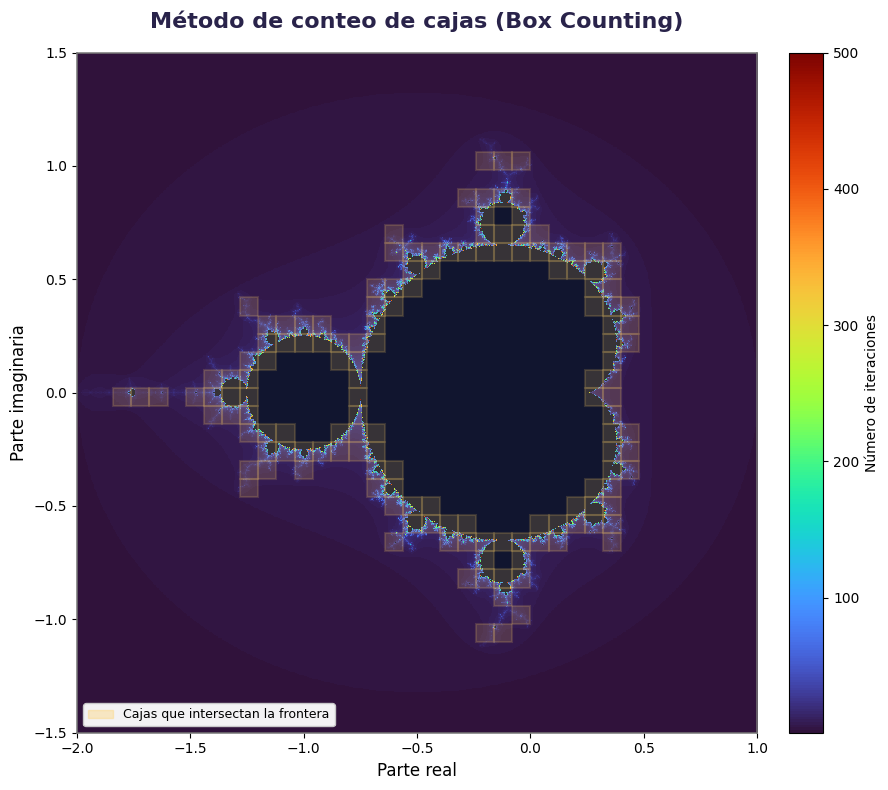

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Patch
from matplotlib.colors import ListedColormap

# ==================================================
# 1. PARÁMETROS
# ==================================================

resolucion = 900
N = 500
tamano_caja = 24

xmin, xmax = -2.0, 1.0
ymin, ymax = -1.5, 1.5

x = np.linspace(xmin, xmax, resolucion)
y = np.linspace(ymin, ymax, resolucion)

X, Y = np.meshgrid(x, y)
C = X + 1j * Y

Z = np.zeros_like(C, dtype=complex)
activos = np.ones(C.shape, dtype=bool)

iteraciones = np.zeros(C.shape, dtype=int)

# ==================================================
# 2. CONSTRUCCIÓN DEL CONJUNTO DE MANDELBROT
# ==================================================

for k in range(1, N + 1):

    Z[activos] = Z[activos]**2 + C[activos]

    escapan = activos & (np.abs(Z) > 2)

    iteraciones[escapan] = k
    activos[escapan] = False

conjunto = activos.copy()

# ==================================================
# 3. IDENTIFICACIÓN DE LA FRONTERA
# ==================================================

frontera = np.zeros_like(conjunto, dtype=bool)

frontera[1:, :] |= conjunto[1:, :] != conjunto[:-1, :]
frontera[:-1, :] |= conjunto[:-1, :] != conjunto[1:, :]

frontera[:, 1:] |= conjunto[:, 1:] != conjunto[:, :-1]
frontera[:, :-1] |= conjunto[:, :-1] != conjunto[:, 1:]

# ==================================================
# 4. REPRESENTACIÓN DEL CONJUNTO
# ==================================================

fig, ax = plt.subplots(figsize=(10, 8))

# Mapa de colores para las iteraciones
colores = plt.cm.turbo(np.linspace(0, 1, 256))
cmap = ListedColormap(colores)
cmap.set_under("#11152F")

datos = iteraciones.astype(float)
datos[conjunto] = 0

imagen = ax.imshow(
    datos,
    extent=[xmin, xmax, ymin, ymax],
    origin="lower",
    cmap=cmap,
    vmin=1,
    vmax=N,
    interpolation="nearest"
)

# ==================================================
# 5. CONTEO DE CAJAS SOBRE LA FRONTERA
# ==================================================

for i in range(0, resolucion, tamano_caja):
    for j in range(0, resolucion, tamano_caja):

        bloque = frontera[
            i:min(i + tamano_caja, resolucion),
            j:min(j + tamano_caja, resolucion)
        ]

        if np.any(bloque):

            x0 = xmin + (xmax - xmin) * j / resolucion
            y0 = ymin + (ymax - ymin) * i / resolucion

            ancho = (xmax - xmin) * min(
                tamano_caja, resolucion - j
            ) / resolucion

            alto = (ymax - ymin) * min(
                tamano_caja, resolucion - i
            ) / resolucion

            caja = Rectangle(
                (x0, y0),
                ancho,
                alto,
                linewidth=1.5,
                edgecolor="#FFD166",
                facecolor="#FFD166",
                alpha=0.16,
                zorder=5
            )

            ax.add_patch(caja)

# ==================================================
# 6. FORMATO DE LA FIGURA
# ==================================================

ax.set_facecolor("#11152F")

ax.set_title(
    "Método de conteo de cajas (Box Counting)",
    fontsize=16,
    fontweight="bold",
    color="#29234A",
    pad=18
)

ax.set_xlabel("Parte real", fontsize=12)
ax.set_ylabel("Parte imaginaria", fontsize=12)

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")
ax.grid(False)

for borde in ax.spines.values():
    borde.set_color("#777777")
    borde.set_linewidth(1.1)

# Barra de color
barra = plt.colorbar(
    imagen,
    ax=ax,
    fraction=0.045,
    pad=0.035
)

barra.set_label(
    "Número de iteraciones",
    fontsize=10
)

# Leyenda
leyenda = Patch(
    facecolor="#FFD166",
    edgecolor="#FFD166",
    alpha=0.35,
    label="Cajas que intersectan la frontera"
)

ax.legend(
    handles=[leyenda],
    loc="lower left",
    fontsize=9,
    framealpha=0.95
)

plt.tight_layout()

# ==================================================
# 7. GUARDAR Y DESCARGAR
# ==================================================

nombre = "box_counting_mandelbrot.png"

plt.savefig(
    nombre,
    dpi=350,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

from google.colab import files
files.download(nombre)

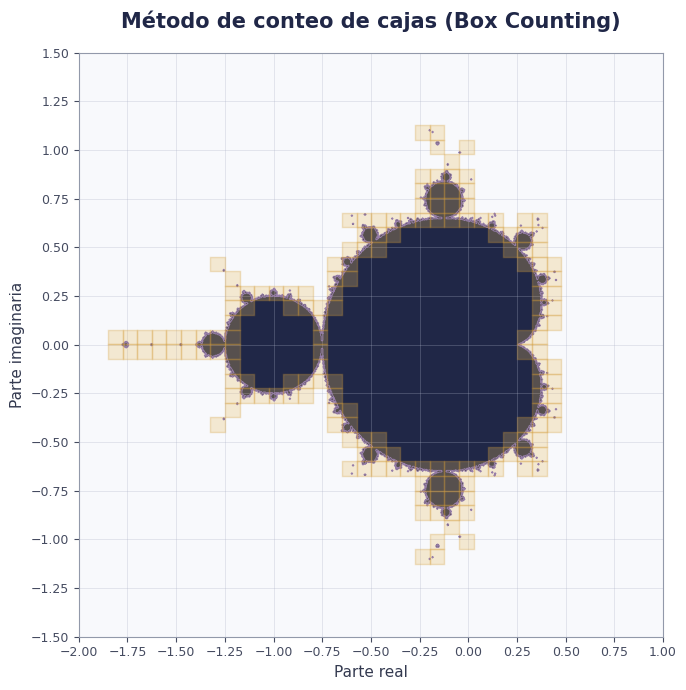

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from matplotlib.colors import ListedColormap

# ==========================================
# 1. PARÁMETROS DEL PLANO COMPLEJO
# ==========================================

resolucion = 1000
N = 500
tamano_caja = 25

xmin, xmax = -2.0, 1.0
ymin, ymax = -1.5, 1.5

x = np.linspace(xmin, xmax, resolucion)
y = np.linspace(ymin, ymax, resolucion)

X, Y = np.meshgrid(x, y)
C = X + 1j * Y

# ==========================================
# 2. CONSTRUCCIÓN DEL CONJUNTO
# ==========================================

Z = np.zeros_like(C, dtype=complex)
activos = np.ones(C.shape, dtype=bool)

for k in range(N):
    Z[activos] = Z[activos]**2 + C[activos]
    activos[np.abs(Z) > 2] = False

conjunto = activos

# ==========================================
# 3. DETECCIÓN NUMÉRICA DE LA FRONTERA
# ==========================================

frontera = np.zeros_like(conjunto, dtype=bool)

frontera[1:, :] |= conjunto[1:, :] != conjunto[:-1, :]
frontera[:-1, :] |= conjunto[:-1, :] != conjunto[1:, :]

frontera[:, 1:] |= conjunto[:, 1:] != conjunto[:, :-1]
frontera[:, :-1] |= conjunto[:, :-1] != conjunto[:, 1:]

# ==========================================
# 4. CONFIGURACIÓN DE LA FIGURA
# ==========================================

fig, ax = plt.subplots(figsize=(10, 7))

ax.set_facecolor("#F8F9FC")

# Conjunto de Mandelbrot
ax.contourf(
    X, Y, conjunto.astype(int),
    levels=[0.5, 1.5],
    colors=["#202747"]
)

# Frontera
ax.contour(
    X, Y, frontera.astype(int),
    levels=[0.5],
    colors=["#7867C5"],
    linewidths=0.65
)

# ==========================================
# 5. CUADRÍCULA DE REFERENCIA
# ==========================================

ax.set_xticks(np.arange(-2, 1.01, 0.25))
ax.set_yticks(np.arange(-1.5, 1.51, 0.25))

ax.grid(
    True,
    color="#AAB1C5",
    linewidth=0.45,
    alpha=0.45,
    linestyle="-"
)

# ==========================================
# 6. CAJAS QUE INTERSECTAN LA FRONTERA
# ==========================================

for i in range(0, resolucion, tamano_caja):
    for j in range(0, resolucion, tamano_caja):

        bloque = frontera[
            i:min(i + tamano_caja, resolucion),
            j:min(j + tamano_caja, resolucion)
        ]

        if np.any(bloque):

            x0 = x[j]
            y0 = y[i]

            ancho = x[min(j + tamano_caja, resolucion - 1)] - x[j]
            alto = y[min(i + tamano_caja, resolucion - 1)] - y[i]

            caja = Rectangle(
                (x0, y0),
                ancho,
                alto,
                linewidth=1.05,
                edgecolor="#D49A35",
                facecolor="#E8BC63",
                alpha=0.28,
                zorder=5
            )

            ax.add_patch(caja)

# ==========================================
# 7. PRESENTACIÓN
# ==========================================

ax.set_title(
    "Método de conteo de cajas (Box Counting)",
    fontsize=15,
    fontweight="bold",
    color="#202747",
    pad=18
)

ax.set_xlabel("Parte real", fontsize=11, color="#343A50")
ax.set_ylabel("Parte imaginaria", fontsize=11, color="#343A50")

ax.set_xlim(xmin, xmax)
ax.set_ylim(ymin, ymax)
ax.set_aspect("equal")

ax.tick_params(labelsize=9, colors="#454B60")

for borde in ax.spines.values():
    borde.set_color("#9299AA")
    borde.set_linewidth(0.8)

plt.tight_layout()

# ==========================================
# 8. GUARDAR IMAGEN
# ==========================================

nombre = "box_counting_mandelbrot.png"

plt.savefig(
    nombre,
    dpi=350,
    bbox_inches="tight",
    facecolor="#F8F9FC"
)

plt.show()

from google.colab import files
files.download(nombre)